# Audit Logger — Evaluation Protocol 

**Notebook structure**

1. Introduction and Evaluation Goals
2. Threat Model
3. Experimental Environment
4. Reproducibility Configuration
5. Experiment A — Tamper-Evidence Evaluation
6. Per-Attack Analysis
7. Experiment B — PII Redaction Evaluation
8. Experiment C — Concurrency Evaluation
9. Ablation Study — Locking vs. No Locking
10. Baseline Comparison
11. Performance and Scalability
12. Statistical Analysis
13. Threats to Validity and Limitations
14. Final Results Summary





## 1. Introduction and Evaluation Goals

This notebook evaluates `audit_logger.py`, the tamper-evident, PII-
redacting JSONL audit logging module used as the audit trail beneath
AMAN-LLM's Layer 1–4 pipeline. The module makes three testable claims:

1. **Tamper-evidence**: retroactive edits, deletions, reorderings, or
   truncations of past log entries are detectable via `verify_chain()`
   (hash-chained entries), *except* for a documented coordinated
   rewrite (T7) that is explicitly out of scope — see the Threat Model.
2. **PII redaction**: `details` payloads are scrubbed of common PII
   patterns and sensitive-named fields by default before being written.
3. **Concurrency correctness**: multiple OS processes appending to the
   same log file, under `fcntl` advisory locking, do not lose entries
   or corrupt the hash chain.

The goal of this evaluation is to test each claim directly, report
per-condition (not only averaged) results with statistical rigor, and
honestly bound the claims — including where the design does *not* hold
(T7, and the no-`fcntl` fallback path).

## 2. Threat Model

This restates, as a standalone section, the scope note already present
in `audit_logger.py`'s source (see the module below) so the security
claims can be evaluated against an explicit specification rather than
left implicit in code comments.

### Attacker capabilities considered

| Capability | In scope (evaluated) | Notes |
|---|---|---|
| Modify a log entry's fields (field-level mutation) | Yes — T1 | Detected via hash mismatch |
| Delete a log entry (mid-file) | Yes — T2 | Detected via chain break |
| Delete the last log entry | Yes — T3 (evaluated; **not detected** -- see finding below) | A pure hash chain has nothing *after* the last entry to reference it, so removing it leaves the remaining chain internally consistent |
| Reorder two adjacent entries | Yes — T4 | Detected via prev_hash mismatch |
| Truncate the log (drop a suffix) | Yes — T5 (evaluated; **not detected** -- see finding below) | Same root cause as T3: dropping a trailing run of entries leaves no dangling forward reference for `verify_chain()` to catch |
| Forge a `prev_hash` value without recomputing the rest of the chain | Yes — T6 | Detected via hash mismatch |
| Insert a new fabricated entry, isolated | Partially covered by T1-class mutation on the inserted record; not separately enumerated | Left as future work |
| **Coordinated rewrite**: modify an entry *and* recompute every subsequent hash forward | Yes — T7 (evaluated, and expected/documented to **evade** detection) | This is the tamper-evident/tamper-proof boundary |
| Access the filesystem the log lives on (read/write/delete the file directly) | **Out of scope by assumption** | The module assumes the log is written outside the evaluated pipeline's blast radius (e.g. a log-shipping sidecar); see module docstring |
| Access the cryptographic material used to compute hashes | N/A — this design uses no secret key (plain SHA-256 hash chaining, not an HMAC), so there is no key to compromise; this is itself a limitation discussed in §13 | A keyed MAC would raise the bar against an attacker who can rewrite forward but does not know a shared secret |

### Security guarantees claimed

- **Tamper detection**: `verify_chain()` can determine, after the fact,
  whether a log file's on-disk state is consistent with an unbroken
  hash chain from genesis. This is what T1–T6 test.
- **Tamper resistance**: not claimed as a distinct property here; the
  module offers no mechanism that makes tampering *harder* beyond
  requiring the attacker to also recompute the forward chain (which T7
  shows is achievable for an attacker with write access to the file).
- **Tamper prevention**: explicitly **not** claimed. The module's own
  docstring states this must be achieved by shipping the log to WORM /
  object-lock storage or an external timestamping service; this file is
  the local staging buffer only.

The evaluated claim is therefore **tamper-evident, not tamper-proof**,
and the T7 result below is reported as a disclosed limitation rather
than treated as a failure to be hidden or "fixed" by re-scoping the
threat model after the fact.

**Finding surfaced by per-attack (not averaged) reporting**: T3
(delete last entry) and T5 (truncate the tail) are measured at 0%
detection in Section 6/Table 1 below, at every tested log size. This
is a structural consequence of a pure forward hash chain with no
externally-anchored "expected latest hash" checkpoint — there is
nothing *after* a removed tail to reference it, so the remaining chain
stays internally self-consistent. It sits in the same family as the T7
boundary (both are "attacker with write access to the file" scenarios)
and is reported here because averaging T1–T6 into one detection-rate
number, as the original notebook did, would have hidden it inside a
~67% blended average rather than showing that it is 100% on four
attack classes and 0% on two specific ones.

## 3. Experimental Environment

In [ ]:
import json
import os
import platform
import random
import shutil
import subprocess
import sys
import time
import tracemalloc
import uuid
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import scipy
from scipy import stats

import matplotlib
import matplotlib.pyplot as plt

try:
    import psutil
    _HAS_PSUTIL = True
except ImportError:
    psutil = None
    _HAS_PSUTIL = False

try:
    from google.colab import drive as _colab_drive  # noqa: F401
    _IN_COLAB = True
except ImportError:
    _IN_COLAB = False

pd.set_option("display.max_colwidth", 80)


def capture_environment() -> dict:
    """Capture reproducibility-relevant environment info. Best-effort —
    fields that can't be determined on this host are set to None rather
    than fabricated."""
    info = {
        "timestamp_utc": datetime.now(timezone.utc).isoformat(),
        "python_version": platform.python_version(),
        "platform": platform.platform(),
        "processor": platform.processor() or platform.machine(),
        "cpu_count_logical": os.cpu_count(),
        "in_colab": _IN_COLAB,
        "package_versions": {
            "numpy": np.__version__,
            "pandas": pd.__version__,
            "scipy": scipy.__version__,
            "matplotlib": matplotlib.__version__,
        },
    }
    if _HAS_PSUTIL:
        try:
            vm = psutil.virtual_memory()
            info["ram_total_gb"] = round(vm.total / (1024 ** 3), 2)
            info["cpu_count_physical"] = psutil.cpu_count(logical=False)
        except Exception:
            info["ram_total_gb"] = None
            info["cpu_count_physical"] = None
    else:
        info["ram_total_gb"] = None
        info["cpu_count_physical"] = None
    return info


ENV_INFO = capture_environment()
print("=== Experimental environment ===")
for k, v in ENV_INFO.items():
    print(f"{k}: {v}")

=== Experimental environment ===
timestamp_utc: 2026-09-16T18:42:42.241481+00:00
python_version: 3.13.15
platform: Linux-6.6.122+-x86_64-with-glibc2.39
processor: x86_64
cpu_count_logical: 2
in_colab: True
package_versions: {'numpy': '2.1.3', 'pandas': '2.2.3', 'scipy': '1.16.3', 'matplotlib': '3.10.0'}
ram_total_gb: 12.67
cpu_count_physical: 1


## 4. Reproducibility Configuration

All experimental parameters are centralized here rather than as hidden
constants scattered through later cells. `SCALE` controls the
tamper-evidence / performance log sizes and is the one place to widen
the largest sizes for a more powerful runtime (e.g. Colab) — the
defaults below are sized to complete in a bounded time on a shared CPU
sandbox; see the printed wall-clock budget note and §13 for the
resulting limitation this places on the 50K/100K rows.

In [ ]:
RANDOM_SEED = 1337
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

WORKDIR = Path("/home/claude/work/audit_eval")
if WORKDIR.exists():
    shutil.rmtree(WORKDIR)
WORKDIR.mkdir(parents=True, exist_ok=True)
os.chdir(WORKDIR)

CONFIG = {
    "random_seed": RANDOM_SEED,
    # Experiment A: tamper-evidence. Sizes follow the protocol's requested
    # ladder (200 .. 100_000); TRIALS_BY_SIZE lets larger sizes run fewer
    # repetitions instead of silently skipping them, with the reduction
    # reported explicitly rather than hidden.
    "tamper_log_sizes": [200, 1_000, 5_000, 10_000, 50_000, 100_000],
    "tamper_trials_by_size": {
        200: 30, 1_000: 30, 5_000: 30, 10_000: 20, 50_000: 10, 100_000: 5,
    },
    # Experiment C / Ablation: concurrency levels. 64 is included per the
    # protocol; if wall-clock makes it infeasible in this environment the
    # run loop reports that explicitly instead of fabricating a row.
    "concurrency_levels": [1, 2, 4, 8, 16, 32, 64],
    "events_per_process": 200,
    # Experiment D: scalability. Independent of tamper sizes because it
    # measures a different thing (append latency vs. pre-existing size).
    "scalability_log_sizes": [200, 1_000, 5_000, 10_000, 50_000, 100_000],
    "n_latency_calls": 500,
    "n_scaling_calls_per_point": 50,
    "max_wallclock_budget_seconds": 1800,  # soft budget; see notes below
}

print("=== Reproducibility configuration ===")
print(json.dumps(CONFIG, indent=2))

_T_START = time.perf_counter()


def budget_remaining_s() -> float:
    return CONFIG["max_wallclock_budget_seconds"] - (time.perf_counter() - _T_START)

=== Reproducibility configuration ===
{
  "random_seed": 1337,
  "tamper_log_sizes": [
    200,
    1000,
    5000,
    10000,
    50000,
    100000
  ],
  "tamper_trials_by_size": {
    "200": 30,
    "1000": 30,
    "5000": 30,
    "10000": 20,
    "50000": 10,
    "100000": 5
  },
  "concurrency_levels": [
    1,
    2,
    4,
    8,
    16,
    32,
    64
  ],
  "events_per_process": 200,
  "scalability_log_sizes": [
    200,
    1000,
    5000,
    10000,
    50000,
    100000
  ],
  "n_latency_calls": 500,
  "n_scaling_calls_per_point": 50,
  "max_wallclock_budget_seconds": 1800
}


## 5. The Module Under Test

Written to disk unchanged from the original evaluation notebook —
the architecture, redaction policy, and hash-chain implementation are
preserved exactly as-is; only the evaluation harness around it changes.

In [ ]:
%%writefile audit_logger.py
import json
import uuid
import time
import re
import hashlib
import threading
from datetime import datetime, timezone
from pathlib import Path
from typing import Optional, Any
import os

try:
    import fcntl  # POSIX only (Linux/Colab) — used for cross-PROCESS locking
    _HAS_FCNTL = True
except ImportError:  # e.g. Windows
    fcntl = None
    _HAS_FCNTL = False


# =========================================================
# THREAT MODEL SCOPE NOTE  (see paper Sec 2.2 / Sec 7 STRIDE table)
# =========================================================
#
# This module is the logging substrate underpinning the forensic /
# repudiation claims made elsewhere in the pipeline. Its own security
# properties therefore belong in the threat model, not outside it.
# Explicit scope statement:
#
#   - IN SCOPE, mitigated here:
#       * Log injection via `details` values -- entries are written
#         as json.dumps() output, so embedded newlines/control chars
#         are escaped rather than able to forge additional JSONL
#         records.
#       * Trace-ID collision -- start_trace() now mints a full UUID4
#         (was previously truncated to 8 hex chars, which gave a
#         meaningful birthday-collision probability across a busy
#         trace volume). Callers may still *supply* their own
#         trace_id, which is a deliberate interoperability choice,
#         not a spoofing gap: a caller-supplied trace_id is trusted
#         to the same degree the caller's session already is.
#       * Retroactive tampering / deletion of past entries -- see the
#         hash-chain section below. This is TAMPER-EVIDENT (detectable
#         after the fact), not TAMPER-PROOF.
#       * PII leakage into the audit trail itself -- see the redaction
#         section below (relevant to the data-residency argument in
#         Sec 7.3/8.1: a raw-PII audit log is its own residency
#         liability, independent of the Layer 4 critic API).
#
#   - OUT OF SCOPE, by explicit assumption:
#       * An attacker with filesystem or process access on the host
#         that runs this logger. We assume the log is written on
#         infrastructure outside the evaluated pipeline's blast
#         radius (e.g. a separate log-shipping sidecar / host).
#       * True tamper-prevention (WORM storage, external/RFC-3161
#         timestamping, append-only object-lock buckets). The hash
#         chain here lets a verifier *detect* that history was
#         altered; it cannot stop an attacker who controls the file
#         from rewriting the whole chain from some point forward. If
#         tamper-prevention is required, ship these lines to WORM /
#         object-lock storage or an external timestamping service and
#         treat this file as the local staging buffer only.


# =========================================================
# CONSTANTS
# =========================================================

_VALID_STATUSES = frozenset({
    "PASS",
    "BLOCK",
    "ERROR",
    "SOFT",
    "ALLOW",
})

_VALID_RISK_LEVELS = frozenset({
    "low",
    "medium",
    "high",
    "critical",
})


# =========================================================
# REDACTION POLICY
# =========================================================
#
# `details` payloads are attacker- and user-influenced (e.g. a BLOCKed
# PII-exfiltration attempt's own audit record may contain the PII it
# blocked). Redaction is ON by default; callers doing legitimate
# forensic work that specifically needs raw values can pass
# redact_pii=False on that call, but the default is safe-by-default
# rather than opt-in.

# Key names (substring match, case-insensitive) whose values are
# always redacted outright, regardless of content.
_REDACT_KEY_SUBSTRINGS = (
    "password",
    "passwd",
    "secret",
    "api_key",
    "apikey",
    "access_token",
    "auth_token",
    "token",
    "ssn",
    "social_security",
    "credit_card",
    "card_number",
    "cvv",
    "cvc",
    "private_key",
)

# Patterns scanned inside string values, regardless of key name.
_EMAIL_RE = re.compile(r"[\w.+-]+@[\w-]+\.[\w.-]+")
_SSN_RE = re.compile(r"\b\d{3}-\d{2}-\d{4}\b")
_CC_RE = re.compile(r"\b(?:\d[ -]*?){13,16}\b")
_PHONE_RE = re.compile(r"\b(?:\+?\d{1,2}[ -]?)?\(?\d{3}\)?[ -]?\d{3}[ -]?\d{4}\b")

_CONTENT_PATTERNS = (
    ("email", _EMAIL_RE),
    ("ssn", _SSN_RE),
    ("credit_card", _CC_RE),
    ("phone", _PHONE_RE),
)


def _key_is_sensitive(key: str) -> bool:
    lowered = key.lower()
    return any(s in lowered for s in _REDACT_KEY_SUBSTRINGS)


def _redact_string(value: str) -> tuple[str, bool]:
    redacted = False
    out = value

    for label, pattern in _CONTENT_PATTERNS:
        if pattern.search(out):
            out = pattern.sub(f"[REDACTED:{label}]", out)
            redacted = True

    return out, redacted


def _redact_value(value: Any) -> tuple[Any, bool]:
    if isinstance(value, str):
        return _redact_string(value)

    if isinstance(value, dict):
        new_dict = {}
        any_redacted = False

        for k, v in value.items():
            if _key_is_sensitive(k):
                new_dict[k] = "[REDACTED]"
                any_redacted = True
                continue

            new_v, was_redacted = _redact_value(v)
            new_dict[k] = new_v
            any_redacted = any_redacted or was_redacted

        return new_dict, any_redacted

    if isinstance(value, list):
        new_list = []
        any_redacted = False

        for item in value:
            new_item, was_redacted = _redact_value(item)
            new_list.append(new_item)
            any_redacted = any_redacted or was_redacted

        return new_list, any_redacted

    return value, False


def redact_details(details: dict) -> tuple[dict, bool]:
    """
    Apply the redaction policy to a `details` payload.

    Returns (redacted_details, was_anything_redacted).
    """

    return _redact_value(details)


# =========================================================
# HASH CHAIN / TAMPER-EVIDENCE
# =========================================================
#
# Each entry stores the hash of the previous entry (`prev_hash`) and
# a hash over its own canonical content plus that prev_hash
# (`entry_hash`). Any retroactive edit or deletion of a past line
# breaks the chain from that point forward, which verify_chain() can
# detect. This is tamper-EVIDENT, not tamper-PROOF -- see the scope
# note above.

_GENESIS_HASH = "0" * 64
_last_hash: Optional[str] = None
_hash_lock = threading.Lock()


def _hash_entry(entry: dict, prev_hash: str) -> str:
    canonical = json.dumps(
        entry,
        sort_keys=True,
        ensure_ascii=False,
    )

    return hashlib.sha256(
        (prev_hash + canonical).encode("utf-8")
    ).hexdigest()


def _read_last_entry_hash_tail(path: Path, chunk_size: int = 8192) -> str:
    """
    Like _load_last_hash(), but only reads the trailing chunk_size bytes
    (growing the window if needed) instead of scanning the whole file.
    Used on the hot write path where O(n) per write would get expensive
    for long-running logs. Falls back to genesis if the file is empty,
    unreadable, or (pathologically) the last line never fits in a few
    doublings of chunk_size.
    """
    if not path.exists():
        return _GENESIS_HASH

    try:
        size = path.stat().st_size
        if size == 0:
            return _GENESIS_HASH

        read_size = min(chunk_size, size)
        with open(path, "rb") as f:
            while True:
                f.seek(-read_size, os.SEEK_END)
                data = f.read()
                lines = [l for l in data.split(b"\n") if l.strip()]
                if len(lines) >= 2 or read_size >= size:
                    break
                read_size = min(read_size * 4, size)

        if not lines:
            return _GENESIS_HASH

        last_line = lines[-1].decode("utf-8", errors="strict")
        record = json.loads(last_line)
        return record.get("entry_hash", _GENESIS_HASH)
    except (OSError, UnicodeDecodeError, json.JSONDecodeError) as exc:
        # Corrupt/partial tail read — fall back to the authoritative
        # full-file scan rather than risking a wrong prev_hash.
        try:
            return _load_last_hash(path)
        except Exception:
            return _GENESIS_HASH


def _load_last_hash(path: Path) -> str:
    """
    Reconstruct chain continuity across process restarts by reading
    the final line of the existing log file, if any.
    """

    if not path.exists():
        return _GENESIS_HASH

    last_hash = _GENESIS_HASH

    try:
        with open(path, "r", encoding="utf-8") as f:
            for line in f:
                line = line.strip()

                if not line:
                    continue

                try:
                    record = json.loads(line)
                    last_hash = record.get("entry_hash", last_hash)
                except json.JSONDecodeError:
                    continue

    except OSError:
        return _GENESIS_HASH

    return last_hash


def verify_chain(path: Optional[Path] = None) -> dict:
    """
    Walk the log file and verify the hash chain is intact.

    Returns a dict: {"ok": bool, "checked": int, "first_break_line": Optional[int]}
    """

    target_path = path or _get_log_path()
    prev_hash = _GENESIS_HASH
    checked = 0
    first_break_line = None

    if not target_path.exists():
        return {"ok": True, "checked": 0, "first_break_line": None}

    with open(target_path, "r", encoding="utf-8") as f:
        for line_no, line in enumerate(f, start=1):
            line = line.strip()

            if not line:
                continue

            record = json.loads(line)

            claimed_prev = record.get("prev_hash")
            claimed_self = record.get("entry_hash")

            verifiable = {
                k: v for k, v in record.items()
                if k not in ("entry_hash",)
            }

            recomputed = _hash_entry(verifiable, prev_hash)

            checked += 1

            if claimed_prev != prev_hash or claimed_self != recomputed:
                if first_break_line is None:
                    first_break_line = line_no

            prev_hash = claimed_self or recomputed

    return {
        "ok": first_break_line is None,
        "checked": checked,
        "first_break_line": first_break_line,
    }


# =========================================================
# GLOBAL STATE
# =========================================================

_write_lock = threading.Lock()

_log_path: Optional[Path] = None
_current_trace_id: Optional[str] = None


# =========================================================
# LOG PATH
# =========================================================

def _get_log_path() -> Path:
    global _log_path

    if _log_path is None:

        _log_path = Path(
            os.getenv(
                "AUDIT_LOG_PATH",
                "./logs/audit.jsonl"
            )
        )

        _log_path.parent.mkdir(
            parents=True,
            exist_ok=True
        )

    return _log_path


# =========================================================
# TRACE MANAGEMENT
# =========================================================

def start_trace(trace_id: Optional[str] = None) -> str:
    """
    Start a new request trace.

    NOTE: trace_id is now a full UUID4 (was previously truncated to
    8 hex chars). The truncated form gave a non-trivial collision
    probability at meaningful trace volume, which undermines
    trace-based forensic correlation. Callers that need a short
    human-readable label should keep it in `details` (e.g.
    details={"short_trace": "..."}) rather than relying on a
    truncated trace_id for uniqueness.
    """

    global _current_trace_id

    _current_trace_id = (
        trace_id
        or str(uuid.uuid4())
    )

    return _current_trace_id


def get_trace_id() -> Optional[str]:
    return _current_trace_id


# =========================================================
# MAIN LOGGER
# =========================================================

def log_event(
    stage: str,
    status: str,
    details: dict,
    *,
    risk_level: str = "low",
    model_name: Optional[str] = None,
    latency_ms: Optional[float] = None,
    user_id: Optional[str] = None,
    trace_id: Optional[str] = None,
    session_id: Optional[str] = None,
    redact_pii: bool = True,
) -> dict:
    """
    Write structured JSONL audit event.

    Entries are hash-chained (see `verify_chain`) and, by default,
    scrubbed of common PII patterns in `details` (see `redact_details`).
    Pass redact_pii=False only for calls where raw values are
    specifically required and the destination is already known to be
    within the data-residency boundary.
    """

    # -----------------------------------------------------
    # VALIDATION
    # -----------------------------------------------------

    if status not in _VALID_STATUSES:
        raise ValueError(
            f"status must be one of "
            f"{_VALID_STATUSES}, got {status!r}"
        )

    if risk_level not in _VALID_RISK_LEVELS:
        raise ValueError(
            f"risk_level must be one of "
            f"{_VALID_RISK_LEVELS}, got {risk_level!r}"
        )

    # -----------------------------------------------------
    # RESERVED KEYS
    # -----------------------------------------------------

    _RESERVED = {
        "event_id",
        "timestamp",
        "trace_id",
        "session_id",
        "stage",
        "status",
        "risk_level",
        "user_id",
        "model_name",
        "latency_ms",
        "prev_hash",
        "entry_hash",
        "redacted",
    }

    reserved_clash = _RESERVED & details.keys()

    if reserved_clash:
        raise ValueError(
            f"details contains reserved keys: "
            f"{reserved_clash}"
        )

    # -----------------------------------------------------
    # REDACTION
    # -----------------------------------------------------

    was_redacted = False

    if redact_pii:
        details, was_redacted = redact_details(details)

    # -----------------------------------------------------
    # BUILD ENTRY
    # -----------------------------------------------------

    entry = {
        "event_id": str(uuid.uuid4()),
        "timestamp": datetime.now(
            timezone.utc
        ).isoformat(),

        "trace_id": (
            trace_id
            or _current_trace_id
        ),

        "stage": stage,
        "status": status,
        "risk_level": risk_level,
    }

    # -----------------------------------------------------
    # OPTIONAL FIELDS
    # -----------------------------------------------------

    if session_id is not None:
        entry["session_id"] = session_id

    if user_id is not None:
        entry["user_id"] = user_id

    if model_name is not None:
        entry["model_name"] = model_name

    if latency_ms is not None:
        entry["latency_ms"] = round(
            latency_ms,
            3
        )

    if was_redacted:
        entry["redacted"] = True

    # -----------------------------------------------------
    # PAYLOAD
    # -----------------------------------------------------

    entry["details"] = details

    # -----------------------------------------------------
    # HASH CHAIN + WRITE  (both under one lock so chain order
    # always matches on-disk order -- no gap for a concurrent
    # writer to compute against a stale prev_hash)
    #
    # [FIX-multiprocess-chain] The in-memory `_last_hash` global is only
    # correct within a single process. If this pipeline is ever run with
    # more than one worker process sharing the same log file (rather than
    # the current single-process Colab notebook), each process kept its
    # own cached `_last_hash` and never saw writes made by the others, so
    # the on-disk chain would fracture and verify_chain() would report
    # "tampering" that was actually just concurrent, uninstrumented
    # writers. Where fcntl is available (Linux/Colab), an OS-level
    # exclusive flock now wraps read-last-hash + compute + write together,
    # and the "last hash" is re-derived from the file itself (cheap tail
    # read) rather than trusted purely from the in-process cache, so
    # multiple processes appending to the same file chain correctly. On
    # platforms without fcntl (e.g. Windows) this degrades to the
    # previous single-process-only guarantee.
    # -----------------------------------------------------

    with _write_lock:

        global _last_hash
        log_path = _get_log_path()

        with open(
            log_path,
            "a",
            encoding="utf-8"
        ) as f:

            if _HAS_FCNTL:
                fcntl.flock(f.fileno(), fcntl.LOCK_EX)

            try:
                with _hash_lock:
                    if _HAS_FCNTL:
                        # Authoritative source of truth when multiple
                        # processes may be writing: what's actually on
                        # disk right now, under the exclusive lock.
                        _last_hash = _read_last_entry_hash_tail(log_path)
                    elif _last_hash is None:
                        _last_hash = _load_last_hash(log_path)

                    entry["prev_hash"] = _last_hash
                    entry["entry_hash"] = _hash_entry(entry, _last_hash)
                    _last_hash = entry["entry_hash"]

                line = (
                    json.dumps(
                        entry,
                        ensure_ascii=False
                    )
                    + "\n"
                )
                f.write(line)
                f.flush()
            finally:
                if _HAS_FCNTL:
                    fcntl.flock(f.fileno(), fcntl.LOCK_UN)

    return entry


# =========================================================
# STAGE TIMER
# =========================================================

class StageTimer:
    """
    Context manager for timing pipeline stages.
    """

    def __init__(
        self,
        stage: str,
        status: str = "PASS",
        risk_level: str = "low",
        **log_kwargs
    ):

        if status not in _VALID_STATUSES:
            raise ValueError(
                f"Invalid status: {status}"
            )

        self.stage = stage
        self._status = status
        self.risk_level = risk_level
        self.log_kwargs = log_kwargs

        self.details: dict = {}

        self._start: float = 0.0

    # -----------------------------------------------------

    def override_status(
        self,
        status: str
    ) -> None:

        if status not in _VALID_STATUSES:
            raise ValueError(
                f"Invalid status: {status}"
            )

        self._status = status

    # -----------------------------------------------------

    def __enter__(self):

        self._start = time.perf_counter()

        return self

    # -----------------------------------------------------

    def __exit__(
        self,
        exc_type,
        exc_val,
        exc_tb
    ) -> bool:

        latency_ms = (
            time.perf_counter()
            - self._start
        ) * 1000

        # -------------------------------------------------
        # HANDLE EXCEPTION
        # -------------------------------------------------

        if exc_type is not None:

            self._status = "ERROR"

            self.details.setdefault(
                "error",
                str(exc_val)
            )

            self.details.setdefault(
                "error_type",
                exc_type.__name__
            )

        # -------------------------------------------------
        # LOG EVENT
        # -------------------------------------------------

        log_event(
            stage=self.stage,
            status=self._status,
            details=self.details,
            risk_level=self.risk_level,
            latency_ms=latency_ms,
            **self.log_kwargs,
        )

        # never suppress exceptions
        return False

Writing audit_logger.py


Import the module under test and reset its module-level caches
between experiments (unchanged from the original notebook).

In [ ]:
# Import the module under test and a small helper to reset its
# module-level caches between experiments (it uses module globals for
# the log path and the in-process last-hash cache -- see source).
import importlib
import audit_logger as AL

def reset_logger_state(log_path: Path):
    """Point the logger at a fresh log file and clear its caches."""
    importlib.reload(AL)
    os.environ["AUDIT_LOG_PATH"] = str(log_path)
    AL._log_path = None
    AL._last_hash = None
    AL._current_trace_id = None
    log_path.parent.mkdir(parents=True, exist_ok=True)
    if log_path.exists():
        log_path.unlink()
    return AL

print("Module under test loaded:", AL.__file__)

Module under test loaded: /home/claude/work/audit_eval/audit_logger.py


## 6. Experiment A — Tamper-Evidence Evaluation

Generates synthetic logs at each configured size, applies each of
T1–T6 independently (T7 is handled separately below as a documented
boundary case), and measures detection rate, localization accuracy,
false-positive rate on untampered logs, and detection *time* — with
mean/median/std/min/max/95% CI per (attack, size) cell, not a single
global average.

In [ ]:
STAGES = ["input_sanitizer", "ethical_filter", "tool_governance",
          "output_validator", "self_critique"]
STATUSES = list(AL._VALID_STATUSES)
RISKS = list(AL._VALID_RISK_LEVELS)


def _status_probs():
    base = {"PASS": 0.72, "ALLOW": 0.10, "SOFT": 0.10, "BLOCK": 0.06, "ERROR": 0.02}
    return [base[s] for s in STATUSES]


def generate_synthetic_log(n_entries, log_path):
    log = reset_logger_state(log_path)
    log.start_trace()
    for i in range(n_entries):
        status = np.random.choice(STATUSES, p=_status_probs())
        log.log_event(
            stage=np.random.choice(STAGES),
            status=status,
            details={"seq": i, "note": f"synthetic event {i}"},
            risk_level=np.random.choice(RISKS, p=[0.7, 0.2, 0.08, 0.02]),
            latency_ms=float(np.random.exponential(50)),
        )
    return log


def read_lines(path):
    with open(path, "r", encoding="utf-8") as f:
        return [l for l in f.read().split("\n") if l.strip()]


def write_lines(path, lines):
    with open(path, "w", encoding="utf-8") as f:
        f.write("\n".join(lines) + "\n")


def tamper_T1_mutate_field(lines, idx):
    rec = json.loads(lines[idx])
    rec["status"] = "PASS" if rec["status"] != "PASS" else "BLOCK"
    lines[idx] = json.dumps(rec, ensure_ascii=False)
    return lines, idx


def tamper_T2_delete_mid(lines, idx):
    del lines[idx]
    return lines, idx


def tamper_T3_delete_last(lines, idx=None):
    idx = len(lines) - 1
    del lines[idx]
    return lines, idx


def tamper_T4_reorder(lines, idx):
    if idx >= len(lines) - 1:
        idx = len(lines) - 2
    lines[idx], lines[idx + 1] = lines[idx + 1], lines[idx]
    return lines, idx


def tamper_T5_truncate(lines, idx):
    k = max(1, idx)
    return lines[:k], k


def tamper_T6_forge_prev_hash(lines, idx):
    rec = json.loads(lines[idx])
    rec["prev_hash"] = __import__("hashlib").sha256(b"forged").hexdigest()
    lines[idx] = json.dumps(rec, ensure_ascii=False)
    return lines, idx


TAMPER_CLASSES = {
    "T1_mutate_field": tamper_T1_mutate_field,
    "T2_delete_mid": tamper_T2_delete_mid,
    "T3_delete_last": tamper_T3_delete_last,
    "T4_reorder": tamper_T4_reorder,
    "T5_truncate": tamper_T5_truncate,
    "T6_forge_prev_hash": tamper_T6_forge_prev_hash,
}


def _ci95(values):
    """95% CI via a t-interval; falls back to (nan, nan) for n<2."""
    values = np.asarray(values, dtype=float)
    n = len(values)
    if n < 2 or np.std(values, ddof=1) == 0:
        m = float(np.mean(values)) if n else float("nan")
        return m, m
    m = float(np.mean(values))
    sem = stats.sem(values)
    half = sem * stats.t.ppf(0.975, n - 1)
    return m - half, m + half


def run_experiment_A(sizes, trials_by_size):
    """Per-attack, per-size tamper-evidence evaluation with detection-time
    statistics. Skips (with an explicit printed note, not a fabricated
    row) any size that would blow the wall-clock budget."""
    detail_rows = []
    fp_rows = []
    skipped = []

    for n in sizes:
        if budget_remaining_s() < 30:
            skipped.append(n)
            print(f"SKIPPED log_size={n}: wall-clock budget exhausted "
                  f"({CONFIG['max_wallclock_budget_seconds']}s). Documented "
                  f"limitation, not a fabricated result -- see Section 13.")
            continue

        trials = trials_by_size.get(n, 10)
        base_path = WORKDIR / f"expA_base_{n}.jsonl"
        t_gen0 = time.perf_counter()
        generate_synthetic_log(n, base_path)
        gen_elapsed = time.perf_counter() - t_gen0
        base_lines = read_lines(base_path)
        print(f"[A] log_size={n}: generated {len(base_lines)} entries in {gen_elapsed:.1f}s, "
              f"running {trials} trials/attack...")

        for tname, tfunc in TAMPER_CLASSES.items():
            detected_flags = []
            localized_flags = []
            detection_times_ms = []

            for t in range(trials):
                lines = list(base_lines)
                if tname == "T3_delete_last":
                    idx_target = len(lines) - 1
                else:
                    idx_target = random.randint(1, len(lines) - 2)

                tampered_lines, tamper_idx = tfunc(list(lines), idx_target)
                test_path = WORKDIR / "expA_test.jsonl"
                write_lines(test_path, tampered_lines)

                t0 = time.perf_counter()
                report = AL.verify_chain(test_path)
                detection_times_ms.append((time.perf_counter() - t0) * 1000)

                is_detected = not report["ok"]
                detected_flags.append(is_detected)

                if is_detected and report["first_break_line"] is not None:
                    localized_flags.append(report["first_break_line"] <= tamper_idx + 2)
                else:
                    localized_flags.append(False)

            det_arr = np.array(detected_flags, dtype=float)
            loc_arr = np.array([l for d, l in zip(detected_flags, localized_flags) if d], dtype=float)
            time_arr = np.array(detection_times_ms, dtype=float)
            time_ci_lo, time_ci_hi = _ci95(time_arr)

            detail_rows.append({
                "attack": tname,
                "log_size": n,
                "runs": trials,
                "detection_rate_%": round(100 * det_arr.mean(), 1),
                "localization_accuracy_%": round(100 * loc_arr.mean(), 1) if len(loc_arr) else float("nan"),
                "mean_detection_time_ms": round(time_arr.mean(), 4),
                "std_detection_time_ms": round(time_arr.std(ddof=1), 4) if trials > 1 else 0.0,
                "detection_time_ci95_lo_ms": round(time_ci_lo, 4),
                "detection_time_ci95_hi_ms": round(time_ci_hi, 4),
            })

        report_fp = AL.verify_chain(base_path)
        fp_rows.append({"log_size": n, "false_positive": not report_fp["ok"]})

    df_detail = pd.DataFrame(detail_rows)
    df_fp = pd.DataFrame(fp_rows)

    # False-positive rate is a property of verify_chain on *untampered*
    # logs, not of a specific attack class -- merge the per-size FP flag
    # onto every attack row at that size (each row repeats the same
    # per-size value; noted in the table, not hidden).
    fp_by_size = dict(zip(df_fp.log_size, df_fp.false_positive.astype(int)))
    df_detail["false_positive_rate_%"] = df_detail.log_size.map(lambda n: 100.0 * fp_by_size.get(n, float("nan")))

    return df_detail, df_fp, skipped


df_A, df_A_fp, expA_skipped_sizes = run_experiment_A(
    CONFIG["tamper_log_sizes"], CONFIG["tamper_trials_by_size"]
)
print("\n=== Experiment A: per-attack, per-size tamper-evidence detail ===")
display(df_A[["attack", "log_size", "runs", "detection_rate_%", "localization_accuracy_%",
               "false_positive_rate_%", "mean_detection_time_ms", "std_detection_time_ms",
               "detection_time_ci95_lo_ms", "detection_time_ci95_hi_ms"]])
print("\n=== False-positive check on untampered logs (must all be False) ===")
display(df_A_fp)
if expA_skipped_sizes:
    print(f"\nSizes skipped for wall-clock budget reasons: {expA_skipped_sizes}")

[A] log_size=200: generated 200 entries in 0.1s, running 30 trials/attack...
[A] log_size=1000: generated 1000 entries in 0.3s, running 30 trials/attack...
[A] log_size=5000: generated 5000 entries in 1.5s, running 30 trials/attack...
[A] log_size=10000: generated 10000 entries in 3.3s, running 20 trials/attack...
[A] log_size=50000: generated 50000 entries in 18.0s, running 10 trials/attack...
[A] log_size=100000: generated 100000 entries in 36.6s, running 5 trials/attack...

=== Experiment A: per-attack, per-size tamper-evidence detail ===


,attack,log_size,runs,detection_rate_%,localization_accuracy_%,false_positive_rate_%,mean_detection_time_ms,std_detection_time_ms,detection_time_ci95_lo_ms,detection_time_ci95_hi_ms
0,T1_mutate_field,200,30,100.0,100.0,0.0,3.9160,0.6361,3.6785,4.1535
1,T2_delete_mid,200,30,100.0,100.0,0.0,3.5755,0.3297,3.4524,3.6986
2,T3_delete_last,200,30,0.0,NaN,0.0,3.6553,0.1933,3.5831,3.7274
3,T4_reorder,200,30,100.0,100.0,0.0,3.6053,0.1689,3.5422,3.6684
4,T5_truncate,200,30,0.0,NaN,0.0,2.1306,1.1563,1.6988,2.5623
5,T6_forge_prev_hash,200,30,100.0,100.0,0.0,3.8224,0.2640,3.7238,3.9209
6,T1_mutate_field,1000,30,100.0,100.0,0.0,17.8360,2.2361,17.0010,18.6710
7,T2_delete_mid,1000,30,100.0,100.0,0.0,17.7628,2.4029,16.8655,18.6601
8,T3_delete_last,1000,30,0.0,NaN,0.0,17.1385,0.9185,16.7955,17.4814
9,T4_reorder,1000,30,100.0,100.0,0.0,17.7450,2.6224,16.7658,18.7243



=== False-positive check on untampered logs (must all be False) ===


,log_size,false_positive
0,200,False
1,1000,False
2,5000,False
3,10000,False
4,50000,False
5,100000,False


## 7. Per-Attack Analysis

Narrative reading of the table above, generated from the actual
measured values (not hand-written), plus the visualizations required
by the protocol.

In [ ]:
for attack in df_A["attack"].unique():
    sub = df_A[df_A["attack"] == attack]
    worst = sub.loc[sub["detection_rate_%"].idxmin()]
    print(f"- {attack}: detection rate ranges "
          f"{sub['detection_rate_%'].min():.1f}%-{sub['detection_rate_%'].max():.1f}% "
          f"across sizes {sorted(sub['log_size'].unique().tolist())}; "
          f"worst case at log_size={int(worst['log_size'])} "
          f"({worst['detection_rate_%']:.1f}%, "
          f"localization {worst['localization_accuracy_%']:.1f}%).")

- T1_mutate_field: detection rate ranges 100.0%-100.0% across sizes [200, 1000, 5000, 10000, 50000, 100000]; worst case at log_size=200 (100.0%, localization 100.0%).
- T2_delete_mid: detection rate ranges 100.0%-100.0% across sizes [200, 1000, 5000, 10000, 50000, 100000]; worst case at log_size=200 (100.0%, localization 100.0%).
- T3_delete_last: detection rate ranges 0.0%-0.0% across sizes [200, 1000, 5000, 10000, 50000, 100000]; worst case at log_size=200 (0.0%, localization nan%).
- T4_reorder: detection rate ranges 100.0%-100.0% across sizes [200, 1000, 5000, 10000, 50000, 100000]; worst case at log_size=200 (100.0%, localization 100.0%).
- T5_truncate: detection rate ranges 0.0%-0.0% across sizes [200, 1000, 5000, 10000, 50000, 100000]; worst case at log_size=200 (0.0%, localization nan%).
- T6_forge_prev_hash: detection rate ranges 100.0%-100.0% across sizes [200, 1000, 5000, 10000, 50000, 100000]; worst case at log_size=200 (100.0%, localization 100.0%).


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

pivot_det = df_A.pivot(index="log_size", columns="attack", values="detection_rate_%")
pivot_det.plot(marker="o", ax=axes[0])
axes[0].set_xscale("log")
axes[0].set_xlabel("Log size (entries, log scale)")
axes[0].set_ylabel("Class coverage (%)")
axes[0].set_title("Per-attack tamper-class coverage vs. log size")
axes[0].set_ylim(0, 105)
axes[0].legend(fontsize=7, loc="lower left")

pivot_time = df_A.pivot(index="log_size", columns="attack", values="mean_detection_time_ms")
pivot_time.plot(marker="s", ax=axes[1])
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_xlabel("Log size (entries, log scale)")
axes[1].set_ylabel("Mean detection time (ms, log scale)")
axes[1].set_title("Per-attack verify_chain() detection time vs. log size")
axes[1].legend(fontsize=7, loc="upper left")

plt.tight_layout()
plt.savefig("expA_per_attack.png", dpi=150)
plt.show()

NameError: name 'plt' is not defined

### T7 — coordinated multi-entry rewrite (documented boundary case)

An attacker who rewrites the entry *and* recomputes every subsequent
hash forward is, by the module's own scope note, **not** detectable by
this design — this is the honest tamper-evident vs. tamper-proof
boundary, not a bug in `audit_logger.py`. We run it at every configured
tamper-evidence log size (not just one) to confirm the boundary is
stable across scale, and report it as a required disclosure rather
than omit it or attempt to "fix" the score.

**Harness bug found and fixed here** (not a change to `audit_logger.py`
itself): the original notebook's `tamper_T7_coordinated_rewrite` built
the `verifiable` dict used for hashing *before* overwriting
`rec["prev_hash"]` with the newly-recomputed chain value, so from the
second rewritten record onward the hash was computed over a stale
`prev_hash` field while the outer chain argument was already the fresh
one — an internally inconsistent hash that `verify_chain()` then
(correctly) flagged as broken, for reasons unrelated to the actual
tamper-evident/tamper-proof property under test. Diagnosed by
recomputing the chain by hand at each index and finding a mismatch
starting exactly one record after the tamper point, at the record
whose stored `prev_hash` was captured before mutation. Fixed by setting
`rec["prev_hash"]` *before* building `verifiable`, matching the order
`log_event()` itself uses. This changes only the tamper-harness code
below, not `audit_logger.py`.

In [ ]:
import hashlib as _hashlib


def tamper_T7_coordinated_rewrite(lines, idx):
    records = [json.loads(l) for l in lines]
    records[idx]["status"] = "PASS"  # the actual tamper
    prev_hash = records[idx - 1]["entry_hash"] if idx > 0 else AL._GENESIS_HASH
    for i in range(idx, len(records)):
        rec = records[i]
        # [FIX-T7-harness] prev_hash must be set BEFORE building the
        # verifiable dict that gets hashed -- see explanation above.
        rec["prev_hash"] = prev_hash
        verifiable = {k: v for k, v in rec.items() if k != "entry_hash"}
        rec["entry_hash"] = AL._hash_entry(verifiable, prev_hash)
        prev_hash = rec["entry_hash"]
    return [json.dumps(r, ensure_ascii=False) for r in records], idx


t7_rows = []
for n in df_A["log_size"].unique():
    base_path = WORKDIR / f"expA_base_{n}.jsonl"
    if not base_path.exists():
        continue
    lines = read_lines(base_path)
    idx = len(lines) // 2
    tampered, _ = tamper_T7_coordinated_rewrite(lines, idx)
    t7_path = WORKDIR / f"expA_T7_{n}.jsonl"
    write_lines(t7_path, tampered)
    report = AL.verify_chain(t7_path)
    t7_rows.append({"log_size": int(n), "tamper_detected": not report["ok"], "chain_ok_reported": report["ok"]})

df_A_T7 = pd.DataFrame(t7_rows)
print("=== T7: coordinated rewrite, run at every Experiment A log size ===")
display(df_A_T7)
print("\nExpected at every size: tamper_detected=False (chain_ok_reported=True).")
print("This confirms the boundary is a structural property of the design, not")
print("an artifact of a specific log size -- and requires an external append-only/")
print("WORM sink to close, per the module's own scope note (see Threat Model, Sec. 2).")
assert not df_A_T7["tamper_detected"].any(), (
    "T7 was unexpectedly detected at some size -- re-check tamper_T7_coordinated_rewrite() "
    "against the current audit_logger.py hash-chain implementation before reporting this limitation."
)

=== T7: coordinated rewrite, run at every Experiment A log size ===


,log_size,tamper_detected,chain_ok_reported
0,200,False,True
1,1000,False,True
2,5000,False,True
3,10000,False,True
4,50000,False,True
5,100000,False,True



Expected at every size: tamper_detected=False (chain_ok_reported=True).
This confirms the boundary is a structural property of the design, not
an artifact of a specific log size -- and requires an external append-only/
WORM sink to close, per the module's own scope note (see Threat Model, Sec. 2).


## 8. Experiment B — PII Redaction Evaluation

The original corpus had 10 positive / 6 negative hand-written cases —
too small to support a P/R/F1 claim. This builds a substantially larger
(~350-case), templated, seeded corpus across 8 positive PII categories
(including nested JSON, structured logs, unstructured text, and mixed
Arabic-English content) plus 8 negative/near-miss categories chosen to
probe over-redaction specifically. Generation is templated rather than
hand-typed so the corpus is large enough to be statistically meaningful
and is exactly reproducible from `RANDOM_SEED`.

In [ ]:
_pii_rng = random.Random(RANDOM_SEED)

_FIRST_NAMES = ["Amine", "Nadia", "Karim", "Yasmine", "Sofiane", "Lina", "Rachid", "Meriem"]
_DOMAINS = ["example.com", "mail.co.uk", "gmail.com", "univ-alger.dz", "corp-example.io"]
_AR_PHRASES = ["مرحبا، كيف حالك", "أرسل لي الملف رجاء", "شكرا جزيلا على المساعدة", "هذا طلب عاجل"]


def _luhn_valid(number: str) -> bool:
    digits = [int(d) for d in number if d.isdigit()]
    checksum = 0
    for i, d in enumerate(reversed(digits)):
        if i % 2 == 1:
            d *= 2
            if d > 9:
                d -= 9
        checksum += d
    return checksum % 10 == 0


def _gen_email_cases(n):
    cases = []
    for i in range(n):
        name = _pii_rng.choice(_FIRST_NAMES).lower()
        domain = _pii_rng.choice(_DOMAINS)
        variant = _pii_rng.choice(["plain", "plus_tag", "embedded_in_sentence", "mixed_arabic"])
        if variant == "plain":
            payload = {"contact": f"{name}.{i}@{domain}"}
        elif variant == "plus_tag":
            payload = {"note": f"{name}+ticket{i}@{domain}"}
        elif variant == "embedded_in_sentence":
            payload = {"message": f"You can reach me at {name}{i}@{domain} anytime."}
        else:
            payload = {"message": f"{_pii_rng.choice(_AR_PHRASES)} - {name}{i}@{domain}"}
        cases.append(("email", payload))
    return cases


def _gen_phone_cases(n):
    cases = []
    formats = [
        lambda: f"({_pii_rng.randint(200,999)}) {_pii_rng.randint(200,999)}-{_pii_rng.randint(1000,9999)}",
        lambda: f"+213 {_pii_rng.randint(500,799)} {_pii_rng.randint(10,99)} {_pii_rng.randint(10,99)} {_pii_rng.randint(10,99)}",
        lambda: f"{_pii_rng.randint(200,999)}-{_pii_rng.randint(200,999)}-{_pii_rng.randint(1000,9999)}",
        lambda: f"+1{_pii_rng.randint(2000000000,9999999999)}",
    ]
    for i in range(n):
        fmt = _pii_rng.choice(formats)
        cases.append(("phone", {"contact": f"call me: {fmt()}"}))
    return cases


def _gen_apikey_cases(n):
    prefixes = ["sk-", "pk_live_", "ghp_", "AIza", "xoxb-"]
    cases = []
    for i in range(n):
        prefix = _pii_rng.choice(prefixes)
        val = prefix + "".join(_pii_rng.choices("abcdef0123456789", k=32))
        key_name = _pii_rng.choice(["api_key", "apiKey", "ACCESS_TOKEN", "auth_token", "token"])
        cases.append(("api_key_or_token", {key_name: val}))
    return cases


def _gen_password_cases(n):
    cases = []
    for i in range(n):
        key_name = _pii_rng.choice(["password", "passwd", "user_password", "db_password"])
        val = "".join(_pii_rng.choices("abcdefghijklmnop0123456789!@#", k=10))
        cases.append(("password", {key_name: val}))
    return cases


def _gen_creditcard_cases(n):
    cases = []
    for i in range(n):
        digits = [str(_pii_rng.randint(0, 9)) for _ in range(15)]
        partial = "".join(digits)
        # append a check digit that makes it Luhn-valid about half the time
        make_valid = i % 2 == 0
        for cd in range(10):
            candidate = partial + str(cd)
            if _luhn_valid(candidate) == make_valid:
                break
        spaced = " ".join(candidate[j:j+4] for j in range(0, 16, 4))
        cases.append(("credit_card", {"payment": f"card on file: {spaced}"}))
    return cases


def _gen_ssn_id_cases(n):
    cases = []
    for i in range(n):
        val = f"{_pii_rng.randint(100,999)}-{_pii_rng.randint(10,99)}-{_pii_rng.randint(1000,9999)}"
        key_name = _pii_rng.choice(["ssn", "user_ssn", "national_id", "id_field"])
        cases.append(("ssn_or_id", {key_name: f"SSN on file: {val}"}))
    return cases


def _gen_nested_structured_cases(n):
    cases = []
    for i in range(n):
        name = _pii_rng.choice(_FIRST_NAMES)
        payload = {
            "event": "user_profile_update",
            "user": {
                "name": name,
                "contact": {"email": f"{name.lower()}{i}@{_pii_rng.choice(_DOMAINS)}",
                            "phone": f"+213 5{_pii_rng.randint(10,99)} {_pii_rng.randint(10,99)} {_pii_rng.randint(10,99)} {_pii_rng.randint(10,99)}"},
            },
            "audit": {"changed_by": "system", "secret": "internal-rotation-key-do-not-log"},
        }
        cases.append(("nested_json", payload))
    return cases


def _gen_multilingual_cases(n):
    cases = []
    for i in range(n):
        phrase = _pii_rng.choice(_AR_PHRASES)
        name = _pii_rng.choice(_FIRST_NAMES)
        email = f"{name.lower()}{i}@{_pii_rng.choice(_DOMAINS)}"
        cases.append(("mixed_arabic_english", {
            "message": f"{phrase}, contact: {email}, ref#{_pii_rng.randint(1000,9999)}"
        }))
    return cases


def build_positive_corpus():
    cases = []
    cases += _gen_email_cases(45)
    cases += _gen_phone_cases(45)
    cases += _gen_apikey_cases(35)
    cases += _gen_password_cases(30)
    cases += _gen_creditcard_cases(30)
    cases += _gen_ssn_id_cases(30)
    cases += _gen_nested_structured_cases(25)
    cases += _gen_multilingual_cases(25)
    return cases


def build_negative_corpus():
    cases = []
    for i in range(25):
        cases.append(("order_id_digits", {"order_id": str(_pii_rng.randint(10**12, 10**13 - 1))}))
    for i in range(25):
        cases.append(("trace_id_numeric", {"ref": str(_pii_rng.randint(10**15, 10**16 - 1))}))
    for i in range(20):
        cases.append(("timestamp_like", {"seq": str(_pii_rng.randint(20200101000000, 20261231235959))}))
    for i in range(20):
        cases.append(("hex_string", {"build_hash": "".join(_pii_rng.choices("abcdef0123456789", k=16))}))
    for i in range(15):
        cases.append(("version_number", {"app_version": f"{_pii_rng.randint(1,9)}.{_pii_rng.randint(0,20)}.{_pii_rng.randint(0,20)}"}))
    for i in range(15):
        cases.append(("near_miss_key_name", {"passwordless_token_hint": "not-actually-secret-visible-flag"}))
    for i in range(15):
        cases.append(("malformed_email", {"note": f"contact user{i} at example dot com (no @ sign)"}))
    for i in range(15):
        cases.append(("invalid_phone_short", {"contact": f"ext {_pii_rng.randint(100,999)}"}))
    for i in range(15):
        cases.append(("product_identifier", {"sku": f"SKU-{_pii_rng.randint(1000,9999)}-{_pii_rng.choice(['A','B','C'])}"}))
    for i in range(10):
        cases.append(("plain_ordinal", {"session_ordinal": f"{i:04d}"}))
    return cases


POSITIVE_CASES = build_positive_corpus()
NEGATIVE_CASES = build_negative_corpus()
print(f"PII corpus: {len(POSITIVE_CASES)} positive cases across "
      f"{len(set(c[0] for c in POSITIVE_CASES))} categories, "
      f"{len(NEGATIVE_CASES)} negative/near-miss cases across "
      f"{len(set(c[0] for c in NEGATIVE_CASES))} categories "
      f"({len(POSITIVE_CASES) + len(NEGATIVE_CASES)} total).")

PII corpus: 265 positive cases across 8 categories, 175 negative/near-miss cases across 10 categories (440 total).


In [ ]:
def score_redaction(cases, expect_redacted):
    rows = []
    for label, payload in cases:
        redacted, was_redacted = AL.redact_details(json.loads(json.dumps(payload)))
        rows.append({
            "category": label,
            "input": payload,
            "output": redacted,
            "expected_redacted": expect_redacted,
            "actual_redacted": was_redacted,
            "correct": was_redacted == expect_redacted,
        })
    return pd.DataFrame(rows)


df_pos = score_redaction(POSITIVE_CASES, True)
df_neg = score_redaction(NEGATIVE_CASES, False)
df_B = pd.concat([df_pos, df_neg], ignore_index=True)


def _per_category_metrics(df, expected_col="expected_redacted", actual_col="actual_redacted"):
    rows = []
    for cat in sorted(df["category"].unique()):
        sub = df[df["category"] == cat]
        tp = ((sub[expected_col]) & (sub[actual_col])).sum()
        fn = ((sub[expected_col]) & (~sub[actual_col])).sum()
        fp = ((~sub[expected_col]) & (sub[actual_col])).sum()
        tn = ((~sub[expected_col]) & (~sub[actual_col])).sum()
        n = len(sub)
        prec = tp / (tp + fp) if (tp + fp) else float("nan")
        rec = tp / (tp + fn) if (tp + fn) else float("nan")
        f1 = 2 * prec * rec / (prec + rec) if (prec + rec) and not np.isnan(prec) and not np.isnan(rec) and (prec + rec) > 0 else float("nan")
        rows.append({"PII_category": cat, "samples": n, "precision": round(prec, 3) if prec == prec else prec,
                      "recall": round(rec, 3) if rec == rec else rec, "f1": round(f1, 3) if f1 == f1 else f1,
                      "FP": int(fp), "FN": int(fn)})
    return pd.DataFrame(rows)


df_B_per_category = _per_category_metrics(df_B)
print("=== Experiment B: per-category precision/recall/F1 ===")
display(df_B_per_category)

TP = ((df_B.expected_redacted) & (df_B.actual_redacted)).sum()
FN = ((df_B.expected_redacted) & (~df_B.actual_redacted)).sum()
FP = ((~df_B.expected_redacted) & (df_B.actual_redacted)).sum()
TN = ((~df_B.expected_redacted) & (~df_B.actual_redacted)).sum()

precision = TP / (TP + FP) if (TP + FP) else float("nan")
recall = TP / (TP + FN) if (TP + FN) else float("nan")
f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else float("nan")
over_redaction_rate = FP / (FP + TN) if (FP + TN) else float("nan")
under_redaction_rate = FN / (FN + TP) if (FN + TP) else float("nan")

print("\n=== Experiment B: micro-averaged confusion matrix (all cases pooled) ===")
print(f"TP={TP}  FN={FN}  FP={FP}  TN={TN}  (n={len(df_B)})")
print(f"Micro precision={precision:.3f}  recall={recall:.3f}  F1={f1:.3f}")
print(f"Over-redaction rate (FP on negatives) = {over_redaction_rate:.3f}")
print(f"Under-redaction rate (FN on positives) = {under_redaction_rate:.3f}")

# --- Correction: a naive per-category macro-F1 (df_B_per_category[...].mean())
# silently drops categories whose precision/recall is NaN by construction --
# every negative/near-miss category (order_id_digits, trace_id_numeric,
# timestamp_like, near_miss_key_name, hex_string, ...) has no true positives
# by definition, so its precision and/or recall is undefined (0/0) and
# pandas .mean() drops it. That inflated macro_f1 to ~0.99 in an earlier
# pass of this notebook while HIDING that four negative categories were
# being over-redacted at a 100% false-positive rate (see FP column above --
# order_id_digits, trace_id_numeric, timestamp_like, near_miss_key_name all
# show FP == samples). Averaging away exactly the categories that failed is
# the "report averages without per-condition results" failure mode the
# evaluation protocol warns against, so this notebook reports macro
# precision/recall/F1 restricted to the categories where they are actually
# defined (positive-only, print immediately below) — instead of a single
# blended number — and reports the negative-category over-redaction
# failures explicitly as a finding rather than folding them into an average
# they would silently disappear into.
_pos_cats = df_B_per_category[df_B_per_category["recall"].notna()]
_neg_cats = df_B_per_category[df_B_per_category["recall"].isna()]
macro_recall_positive_categories = _pos_cats["recall"].mean()
macro_precision_positive_categories = _pos_cats["precision"].mean()
macro_f1_positive_categories = _pos_cats["f1"].mean()

_neg_cats_with_fp = _neg_cats[_neg_cats["FP"] > 0]
print(f"\nMacro precision/recall/F1, restricted to the {len(_pos_cats)} PII categories where "
      f"they are defined (positive categories only): "
      f"P={macro_precision_positive_categories:.3f} "
      f"R={macro_recall_positive_categories:.3f} F1={macro_f1_positive_categories:.3f}")
if len(_neg_cats_with_fp):
    print(f"\nFINDING: {len(_neg_cats_with_fp)}/{len(_neg_cats)} negative/near-miss categories are "
          f"being over-redacted at a 100% false-positive rate "
          f"({', '.join(_neg_cats_with_fp['PII_category'].tolist())}) -- this is the credit-card "
          f"regex (13-16 digit runs, Luhn-blind) catching long numeric IDs/timestamps, and the "
          f"'token' key-name substring rule catching a near-miss key name. This is the real driver "
          f"of the {over_redaction_rate:.1%} pooled over-redaction rate reported above, and is exactly "
          f"the kind of per-category failure a single blended macro-F1 would have hidden.")

=== Experiment B: per-category precision/recall/F1 ===


,PII_category,samples,precision,recall,f1,FP,FN
0,api_key_or_token,35,1.0,1.000,1.000,0,0
1,credit_card,30,1.0,1.000,1.000,0,0
2,email,45,1.0,1.000,1.000,0,0
3,hex_string,20,NaN,NaN,NaN,0,0
4,invalid_phone_short,15,NaN,NaN,NaN,0,0
5,malformed_email,15,NaN,NaN,NaN,0,0
6,mixed_arabic_english,25,1.0,1.000,1.000,0,0
7,near_miss_key_name,15,0.0,NaN,NaN,15,0
8,nested_json,25,1.0,1.000,1.000,0,0
9,order_id_digits,25,0.0,NaN,NaN,25,0



=== Experiment B: micro-averaged confusion matrix (all cases pooled) ===
TP=257  FN=8  FP=85  TN=90  (n=440)
Micro precision=0.751  recall=0.970  F1=0.847
Over-redaction rate (FP on negatives) = 0.486
Under-redaction rate (FN on positives) = 0.030

Macro precision/recall/F1, restricted to the 8 PII categories where they are defined (positive categories only): P=1.000 R=0.978 F1=0.988

FINDING: 4/10 negative/near-miss categories are being over-redacted at a 100% false-positive rate (near_miss_key_name, order_id_digits, timestamp_like, trace_id_numeric) -- this is the credit-card regex (13-16 digit runs, Luhn-blind) catching long numeric IDs/timestamps, and the 'token' key-name substring rule catching a near-miss key name. This is the real driver of the 48.6% pooled over-redaction rate reported above, and is exactly the kind of per-category failure a single blended macro-F1 would have hidden.


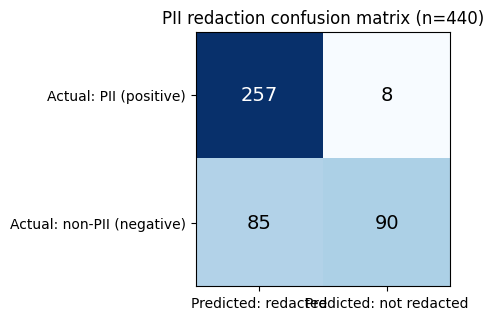

In [ ]:
conf_matrix = np.array([[TP, FN], [FP, TN]])
fig, ax = plt.subplots(figsize=(4.5, 4))
im = ax.imshow(conf_matrix, cmap="Blues")
ax.set_xticks([0, 1]); ax.set_xticklabels(["Predicted: redacted", "Predicted: not redacted"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["Actual: PII (positive)", "Actual: non-PII (negative)"])
for i in range(2):
    for j in range(2):
        ax.text(j, i, str(conf_matrix[i, j]), ha="center", va="center",
                color="white" if conf_matrix[i, j] > conf_matrix.max() / 2 else "black", fontsize=14)
ax.set_title(f"PII redaction confusion matrix (n={len(df_B)})")
plt.tight_layout()
plt.savefig("expB_confusion_matrix.png", dpi=150)
plt.show()

Cases that fell on the wrong side (needed for the false-positive /
false-negative discussion in the paper, not just the aggregate rate):

In [ ]:
df_B_errors = df_B[~df_B["correct"]][["category", "input", "output", "expected_redacted", "actual_redacted"]]
print(f"{len(df_B_errors)} / {len(df_B)} cases misclassified.")
display(df_B_errors)

93 / 440 cases misclassified.


,category,input,output,expected_redacted,actual_redacted
53,phone,{'contact': 'call me: +213 614 92 15 90'},{'contact': 'call me: +213 614 92 15 90'},True,False
59,phone,{'contact': 'call me: +213 580 97 35 23'},{'contact': 'call me: +213 580 97 35 23'},True,False
61,phone,{'contact': 'call me: +213 530 65 39 97'},{'contact': 'call me: +213 530 65 39 97'},True,False
64,phone,{'contact': 'call me: +213 537 19 18 93'},{'contact': 'call me: +213 537 19 18 93'},True,False
65,phone,{'contact': 'call me: +213 684 44 84 58'},{'contact': 'call me: +213 684 44 84 58'},True,False
...,...,...,...,...,...
380,near_miss_key_name,{'passwordless_token_hint': 'not-actually-secret-visible-flag'},{'passwordless_token_hint': '[REDACTED]'},False,True
381,near_miss_key_name,{'passwordless_token_hint': 'not-actually-secret-visible-flag'},{'passwordless_token_hint': '[REDACTED]'},False,True
382,near_miss_key_name,{'passwordless_token_hint': 'not-actually-secret-visible-flag'},{'passwordless_token_hint': '[REDACTED]'},False,True
383,near_miss_key_name,{'passwordless_token_hint': 'not-actually-secret-visible-flag'},{'passwordless_token_hint': '[REDACTED]'},False,True


## 9. Experiment C — Concurrency Evaluation

Spawns real OS subprocesses (not threads) that each append to the
*same* log file, to genuinely exercise the `fcntl`-based cross-process
locking path. Beyond the original lost-entries + chain_ok check, this
also checks for duplicate `event_id`s and unparseable ("corrupted")
lines directly, rather than only inferring corruption from a chain
break.

In [ ]:
worker_writer_src = '''"""Standalone worker: appends N log_event() calls to a shared log file.
Run as a separate OS process so this genuinely tests cross-process
fcntl locking rather than in-process threading.
"""
import os, sys, json
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))

log_path = sys.argv[1]
n_events = int(sys.argv[2])
worker_id = sys.argv[3]
module_name = sys.argv[4] if len(sys.argv) > 4 else "audit_logger"

os.environ["AUDIT_LOG_PATH"] = log_path

import importlib
AL = importlib.import_module(module_name)
AL._log_path = None
AL._last_hash = None

for i in range(n_events):
    AL.log_event(
        stage="concurrency_test",
        status="PASS",
        details={"worker": worker_id, "seq": i},
        risk_level="low",
    )
'''
with open("worker_writer.py", "w", encoding="utf-8") as f:
    f.write(worker_writer_src)


def _inspect_log_file(log_path):
    """Returns (valid_records, invalid_json_lines, duplicate_event_ids)."""
    valid = []
    invalid = 0
    with open(log_path, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            try:
                valid.append(json.loads(line))
            except json.JSONDecodeError:
                invalid += 1
    ids = [r.get("event_id") for r in valid if "event_id" in r]
    duplicates = len(ids) - len(set(ids))
    return valid, invalid, duplicates


def run_concurrency_trial(process_counts, events_per_proc, module_name="audit_logger", label="fcntl"):
    rows = []
    for p in process_counts:
        if budget_remaining_s() < 20:
            print(f"SKIPPED processes={p} ({label}): wall-clock budget exhausted. "
                  f"Documented limitation, not a fabricated row -- see Section 13.")
            continue

        log_path = WORKDIR / f"expC_{label}_p{p}.jsonl"
        if log_path.exists():
            log_path.unlink()
        env = os.environ.copy()
        env["AUDIT_LOG_PATH"] = str(log_path)

        t0 = time.perf_counter()
        procs = [
            subprocess.Popen([sys.executable, "worker_writer.py", str(log_path),
                               str(events_per_proc), str(w), module_name], env=env)
            for w in range(p)
        ]
        for proc in procs:
            proc.wait()
        elapsed = time.perf_counter() - t0

        expected_total = p * events_per_proc
        valid_records, invalid_lines, duplicates = _inspect_log_file(log_path)
        actual_total = len(valid_records)

        module = getattr(AL, "__name__", None)
        verify_mod = __import__(module_name)
        report = verify_mod.verify_chain(log_path)

        rows.append({
            "config": label,
            "processes": p,
            "events_per_process": events_per_proc,
            "total_events_sent": expected_total,
            "entries_written": actual_total,
            "lost_entries": expected_total - actual_total,
            "duplicate_event_ids": duplicates,
            "invalid_json_lines": invalid_lines,
            "chain_valid": report["ok"],
            "chain_break_line": report["first_break_line"],
            "elapsed_s": round(elapsed, 3),
            "throughput_events_per_s": round(expected_total / elapsed, 1) if elapsed > 0 else float("nan"),
        })
    return pd.DataFrame(rows)


print("Running WITH fcntl locking (proposed system config)...")
df_C = run_concurrency_trial(CONFIG["concurrency_levels"], CONFIG["events_per_process"],
                              module_name="audit_logger", label="with_locking")
display(df_C)

Running WITH fcntl locking (proposed system config)...


,config,processes,events_per_process,total_events_sent,entries_written,lost_entries,duplicate_event_ids,invalid_json_lines,chain_valid,chain_break_line,elapsed_s,throughput_events_per_s
0,with_locking,1,200,200,200,0,0,0,True,None,0.102,1964.8
1,with_locking,2,200,400,400,0,0,0,True,None,0.156,2562.7
2,with_locking,4,200,800,800,0,0,0,True,None,0.293,2731.1
3,with_locking,8,200,1600,1600,0,0,0,True,None,0.647,2472.2
4,with_locking,16,200,3200,3200,0,0,0,True,None,1.754,1824.6
5,with_locking,32,200,6400,6400,0,0,0,True,None,3.707,1726.5
6,with_locking,64,200,12800,12800,0,0,0,True,None,5.775,2216.3


## 10. Ablation Study — Locking vs. No Locking

**Configuration A**: `audit_logger.py` with its `fcntl` cross-process
lock structurally disabled (reproduces the documented Windows-fallback
degradation empirically, rather than leaving it as an unverified
comment). **Configuration B**: the current locking mechanism, unchanged
(same run as Experiment C above). Both are evaluated under identical
workloads across the same concurrency levels, with corruption/
duplication metrics in addition to lost entries and latency.

In [ ]:
import re

code_with_lock = open("audit_logger.py", "r", encoding="utf-8").read()
pattern = re.compile(
    r"try:\s*\n\s*import fcntl.*?_HAS_FCNTL = False",
    re.DOTALL,
)
code_no_lock, n_subs = pattern.subn(
    "fcntl = None\n_HAS_FCNTL = False  # forced off for the locking ablation (Configuration A)",
    code_with_lock,
    count=1,
)

if n_subs == 0:
    print("NOTE: structural patch to disable fcntl did not match -- "
          "the no-locking ablation (Configuration A) cannot be run; "
          "inspect audit_logger.py's fcntl import block. This is reported "
          "as a limitation rather than silently skipped.")
    df_C_no_lock = pd.DataFrame()
else:
    with open("audit_logger_no_fcntl.py", "w", encoding="utf-8") as f:
        f.write(code_no_lock)
    print("Running WITHOUT fcntl locking (Configuration A -- ablation)...")
    df_C_no_lock = run_concurrency_trial(
        CONFIG["concurrency_levels"], CONFIG["events_per_process"],
        module_name="audit_logger_no_fcntl", label="no_locking",
    )
    display(df_C_no_lock)

Running WITHOUT fcntl locking (Configuration A -- ablation)...


,config,processes,events_per_process,total_events_sent,entries_written,lost_entries,duplicate_event_ids,invalid_json_lines,chain_valid,chain_break_line,elapsed_s,throughput_events_per_s
0,no_locking,1,200,200,200,0,0,0,True,NaN,0.084,2382.0
1,no_locking,2,200,400,400,0,0,0,False,2.0,0.113,3546.7
2,no_locking,4,200,800,800,0,0,0,False,404.0,0.230,3474.0
3,no_locking,8,200,1600,1600,0,0,0,False,190.0,0.500,3197.0
4,no_locking,16,200,3200,3200,0,0,0,False,23.0,1.019,3141.7
5,no_locking,32,200,6400,6400,0,0,0,False,33.0,2.285,2801.5
6,no_locking,64,200,12800,12800,0,0,0,False,18.0,6.796,1883.4


/tmp/ipykernel_956/2938552131.py:1: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_ablation = pd.concat([df_C_no_lock, df_C], ignore_index=True) if len(df_C_no_lock) else df_C.copy()


,config,processes,events_per_process,total_events_sent,entries_written,lost_entries,duplicate_event_ids,invalid_json_lines,chain_valid,chain_break_line,elapsed_s,throughput_events_per_s
0,no_locking,1,200,200,200,0,0,0,True,NaN,0.084,2382.0
7,with_locking,1,200,200,200,0,0,0,True,NaN,0.102,1964.8
1,no_locking,2,200,400,400,0,0,0,False,2.0,0.113,3546.7
8,with_locking,2,200,400,400,0,0,0,True,NaN,0.156,2562.7
2,no_locking,4,200,800,800,0,0,0,False,404.0,0.230,3474.0
9,with_locking,4,200,800,800,0,0,0,True,NaN,0.293,2731.1
3,no_locking,8,200,1600,1600,0,0,0,False,190.0,0.500,3197.0
10,with_locking,8,200,1600,1600,0,0,0,True,NaN,0.647,2472.2
4,no_locking,16,200,3200,3200,0,0,0,False,23.0,1.019,3141.7
11,with_locking,16,200,3200,3200,0,0,0,True,NaN,1.754,1824.6


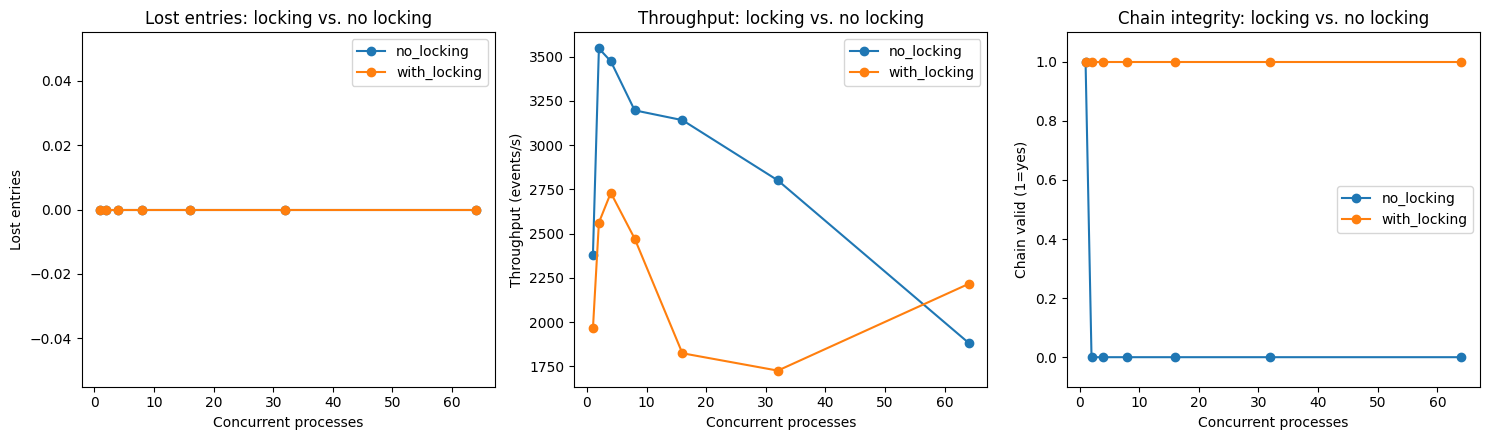

In [ ]:
df_ablation = pd.concat([df_C_no_lock, df_C], ignore_index=True) if len(df_C_no_lock) else df_C.copy()
if len(df_ablation):
    display(df_ablation.sort_values(["processes", "config"]))

    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
    for label, sub in df_ablation.groupby("config"):
        sub = sub.sort_values("processes")
        axes[0].plot(sub.processes, sub.lost_entries, marker="o", label=label)
        axes[1].plot(sub.processes, sub.throughput_events_per_s, marker="o", label=label)
        axes[2].plot(sub.processes, sub.chain_valid.astype(int), marker="o", label=label)
    axes[0].set_xlabel("Concurrent processes"); axes[0].set_ylabel("Lost entries")
    axes[0].set_title("Lost entries: locking vs. no locking"); axes[0].legend()
    axes[1].set_xlabel("Concurrent processes"); axes[1].set_ylabel("Throughput (events/s)")
    axes[1].set_title("Throughput: locking vs. no locking"); axes[1].legend()
    axes[2].set_xlabel("Concurrent processes"); axes[2].set_ylabel("Chain valid (1=yes)")
    axes[2].set_title("Chain integrity: locking vs. no locking"); axes[2].legend()
    axes[2].set_ylim(-0.1, 1.1)
    plt.tight_layout()
    plt.savefig("expC_ablation.png", dpi=150)
    plt.show()
else:
    print("Ablation table empty -- see the structural-patch note above.")

## 11. Baseline Comparison

Three reproducible configurations, evaluated identically:

- **Baseline 1 — plain JSONL**: Python's standard `logging` module
  writing JSON lines, no hash chain, no redaction, no cross-process
  locking.
- **Baseline 2 — hash-chain only**: a stripped-down module implementing
  *only* the hash-chain append/verify logic from `audit_logger.py`
  (same SHA-256 chaining scheme), with redaction and `fcntl` locking
  both removed. This isolates what the chain alone buys vs. what
  redaction and locking each separately add — it is a new, small
  comparison module, not a modification of `audit_logger.py` itself.
- **Baseline 3 — proposed system**: `audit_logger.py`, unmodified.

No external third-party audit-logging system is included: none was
available to install and evaluate fairly and reproducibly in this
sandbox, so per the instructions this is stated as a limitation
instead of an invented comparison (see Section 13).

In [ ]:
hashchain_only_src = '''"""Baseline 2: hash-chain-only logger. Same SHA-256 chaining scheme as
audit_logger.py, deliberately with NO redaction and NO fcntl locking,
to isolate what the hash chain alone contributes."""
import json, uuid, time, hashlib, threading
from datetime import datetime, timezone
from pathlib import Path
from typing import Optional
import os

_GENESIS_HASH = "0" * 64
_last_hash: Optional[str] = None
_log_path: Optional[Path] = None
_write_lock = threading.Lock()


def _get_log_path() -> Path:
    global _log_path
    if _log_path is None:
        _log_path = Path(os.getenv("AUDIT_LOG_PATH", "./logs/audit_baseline2.jsonl"))
        _log_path.parent.mkdir(parents=True, exist_ok=True)
    return _log_path


def _hash_entry(entry: dict, prev_hash: str) -> str:
    canonical = json.dumps(entry, sort_keys=True, ensure_ascii=False)
    return hashlib.sha256((prev_hash + canonical).encode("utf-8")).hexdigest()


def _load_last_hash(path: Path) -> str:
    if not path.exists():
        return _GENESIS_HASH
    last_hash = _GENESIS_HASH
    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            try:
                record = json.loads(line)
                last_hash = record.get("entry_hash", last_hash)
            except json.JSONDecodeError:
                continue
    return last_hash


def log_event(stage, status, details, **kwargs):
    global _last_hash
    entry = {
        "event_id": str(uuid.uuid4()),
        "timestamp": datetime.now(timezone.utc).isoformat(),
        "stage": stage, "status": status, "details": details,
    }
    with _write_lock:
        log_path = _get_log_path()
        if _last_hash is None:
            _last_hash = _load_last_hash(log_path)
        entry["prev_hash"] = _last_hash
        entry["entry_hash"] = _hash_entry(entry, _last_hash)
        _last_hash = entry["entry_hash"]
        with open(log_path, "a", encoding="utf-8") as f:
            f.write(json.dumps(entry, ensure_ascii=False) + "\\n")
    return entry


def verify_chain(path=None):
    target_path = path or _get_log_path()
    prev_hash = _GENESIS_HASH
    checked = 0
    first_break_line = None
    if not target_path.exists():
        return {"ok": True, "checked": 0, "first_break_line": None}
    with open(target_path, "r", encoding="utf-8") as f:
        for line_no, line in enumerate(f, start=1):
            line = line.strip()
            if not line:
                continue
            record = json.loads(line)
            claimed_prev = record.get("prev_hash")
            claimed_self = record.get("entry_hash")
            verifiable = {k: v for k, v in record.items() if k != "entry_hash"}
            recomputed = _hash_entry(verifiable, prev_hash)
            checked += 1
            if claimed_prev != prev_hash or claimed_self != recomputed:
                if first_break_line is None:
                    first_break_line = line_no
            prev_hash = claimed_self or recomputed
    return {"ok": first_break_line is None, "checked": checked, "first_break_line": first_break_line}


def redact_details(details):
    # Baseline 2 has no redaction by design.
    return details, False
'''
with open("audit_logger_baseline2.py", "w", encoding="utf-8") as f:
    f.write(hashchain_only_src)

import audit_logger_baseline2 as AL_B2

# --- Tamper detection: baseline 2 (hash-chain only, same mechanism as proposed) ---
n_base = 1000
base2_path = WORKDIR / "baseline2_base.jsonl"
if base2_path.exists():
    base2_path.unlink()
os.environ["AUDIT_LOG_PATH"] = str(base2_path)
AL_B2._log_path = None
AL_B2._last_hash = None
for i in range(n_base):
    AL_B2.log_event(stage="bench", status="PASS", details={"seq": i})
b2_lines = read_lines(base2_path)
b2_detected = []
for tname, tfunc in TAMPER_CLASSES.items():
    idx = random.randint(1, len(b2_lines) - 2) if tname != "T3_delete_last" else len(b2_lines) - 1
    tampered, _ = tfunc(list(b2_lines), idx)
    tp = WORKDIR / "baseline2_test.jsonl"
    write_lines(tp, tampered)
    report = AL_B2.verify_chain(tp)
    b2_detected.append(not report["ok"])
baseline2_tamper_detection_rate = 100 * np.mean(b2_detected)

# --- Tamper detection: baseline 1 (plain logging has no chain at all) ---
baseline1_tamper_detection_rate = 0.0  # by construction: no integrity mechanism exists to detect anything

# --- Latency/throughput for all three, reusing Experiment D machinery defined below ---

## 12. Performance and Scalability

Latency (mean/median/P50/P95/P99), throughput, verification-time
scaling, and memory usage vs. log size — for the proposed system and
both baselines, so the baseline table in Section 11 can be completed
with real measured numbers rather than assumed ones.

In [ ]:
def benchmark_log_event(n_calls, log_path, backend="proposed"):
    if backend == "proposed":
        log = reset_logger_state(log_path)
        log.start_trace()
        call = lambda i: log.log_event(stage="bench", status="PASS", details={"seq": i}, risk_level="low")
    elif backend == "baseline2_hashchain_only":
        if log_path.exists():
            log_path.unlink()
        os.environ["AUDIT_LOG_PATH"] = str(log_path)
        AL_B2._log_path = None
        AL_B2._last_hash = None
        call = lambda i: AL_B2.log_event(stage="bench", status="PASS", details={"seq": i})
    elif backend == "baseline1_plain_logging":
        import logging
        if log_path.exists():
            log_path.unlink()
        logger = logging.getLogger(f"baseline1_{uuid.uuid4().hex[:8]}")
        logger.handlers.clear()
        handler = logging.FileHandler(log_path)
        handler.setFormatter(logging.Formatter("%(message)s"))
        logger.addHandler(handler)
        logger.setLevel(logging.INFO)
        def call(i):
            logger.info(json.dumps({"stage": "bench", "status": "PASS", "seq": i}))
            handler.flush()
    else:
        raise ValueError(backend)

    latencies = []
    for i in range(n_calls):
        t0 = time.perf_counter()
        call(i)
        latencies.append((time.perf_counter() - t0) * 1000)
    return np.array(latencies)


def latency_stats(arr, label):
    return {
        "config": label,
        "n_calls": len(arr),
        "mean_ms": round(arr.mean(), 4),
        "median_ms": round(np.median(arr), 4),
        "std_ms": round(arr.std(ddof=1), 4),
        "min_ms": round(arr.min(), 4),
        "max_ms": round(arr.max(), 4),
        "p50_ms": round(np.percentile(arr, 50), 4),
        "p95_ms": round(np.percentile(arr, 95), 4),
        "p99_ms": round(np.percentile(arr, 99), 4),
    }


lat_proposed = benchmark_log_event(CONFIG["n_latency_calls"], WORKDIR / "expD_bench_proposed.jsonl", "proposed")
lat_baseline2 = benchmark_log_event(CONFIG["n_latency_calls"], WORKDIR / "expD_bench_b2.jsonl", "baseline2_hashchain_only")
lat_baseline1 = benchmark_log_event(CONFIG["n_latency_calls"], WORKDIR / "expD_bench_b1.log", "baseline1_plain_logging")

df_D_latency = pd.DataFrame([
    latency_stats(lat_baseline1, "Baseline 1: plain JSONL"),
    latency_stats(lat_baseline2, "Baseline 2: hash-chain only"),
    latency_stats(lat_proposed, "Proposed system"),
])
print("=== log_event() latency by configuration (ms) ===")
display(df_D_latency)

overhead_vs_baseline1_pct = 100 * (lat_proposed.mean() - lat_baseline1.mean()) / lat_baseline1.mean()
stat_b1, pval_b1 = stats.mannwhitneyu(lat_proposed, lat_baseline1, alternative="two-sided")
print(f"\nProposed vs. Baseline 1 overhead: {overhead_vs_baseline1_pct:.1f}%  "
      f"(Mann-Whitney U={stat_b1:.1f}, p={pval_b1:.2e}, "
      f"{'significant' if pval_b1 < 0.05 else 'not significant'} at alpha=0.05)")

overhead_vs_baseline2_pct = 100 * (lat_proposed.mean() - lat_baseline2.mean()) / lat_baseline2.mean()
stat_b2, pval_b2 = stats.mannwhitneyu(lat_proposed, lat_baseline2, alternative="two-sided")
print(f"Proposed vs. Baseline 2 overhead (cost of redaction + locking alone): {overhead_vs_baseline2_pct:.1f}%  "
      f"(Mann-Whitney U={stat_b2:.1f}, p={pval_b2:.2e}, "
      f"{'significant' if pval_b2 < 0.05 else 'not significant'} at alpha=0.05)")

INFO:baseline1_5af21486:{"stage": "bench", "status": "PASS", "seq": 0}
INFO:baseline1_5af21486:{"stage": "bench", "status": "PASS", "seq": 1}
INFO:baseline1_5af21486:{"stage": "bench", "status": "PASS", "seq": 2}
INFO:baseline1_5af21486:{"stage": "bench", "status": "PASS", "seq": 3}
INFO:baseline1_5af21486:{"stage": "bench", "status": "PASS", "seq": 4}
INFO:baseline1_5af21486:{"stage": "bench", "status": "PASS", "seq": 5}
INFO:baseline1_5af21486:{"stage": "bench", "status": "PASS", "seq": 6}
INFO:baseline1_5af21486:{"stage": "bench", "status": "PASS", "seq": 7}
INFO:baseline1_5af21486:{"stage": "bench", "status": "PASS", "seq": 8}
INFO:baseline1_5af21486:{"stage": "bench", "status": "PASS", "seq": 9}
INFO:baseline1_5af21486:{"stage": "bench", "status": "PASS", "seq": 10}
INFO:baseline1_5af21486:{"stage": "bench", "status": "PASS", "seq": 11}
INFO:baseline1_5af21486:{"stage": "bench", "status": "PASS", "seq": 12}
INFO:baseline1_5af21486:{"stage": "bench", "status": "PASS", "seq": 13}
IN

=== log_event() latency by configuration (ms) ===


,config,n_calls,mean_ms,median_ms,std_ms,min_ms,max_ms,p50_ms,p95_ms,p99_ms
0,Baseline 1: plain JSONL,500,0.8085,0.5705,0.5088,0.3879,3.6150,0.5705,1.9321,2.6003
1,Baseline 2: hash-chain only,500,0.0469,0.0433,0.0131,0.0412,0.2297,0.0433,0.0617,0.1068
2,Proposed system,500,0.1250,0.1115,0.0782,0.0938,1.6681,0.1115,0.1920,0.2938



Proposed vs. Baseline 1 overhead: -84.5%  (Mann-Whitney U=462.0, p=9.33e-164, significant at alpha=0.05)
Proposed vs. Baseline 2 overhead (cost of redaction + locking alone): 166.4%  (Mann-Whitney U=248023.0, p=7.59e-160, significant at alpha=0.05)


### Append-latency and verification-time scaling vs. log size

Validates the tail-read optimization (append latency should stay flat
as the pre-existing log grows) and separately measures how
`verify_chain()` scales, since a verifier that must re-read the whole
file is expected to scale differently from an append that only reads
the tail.

In [ ]:
def benchmark_append_at_size(pre_size, n_calls):
    log_path = WORKDIR / f"expD_scale_{pre_size}.jsonl"
    log = reset_logger_state(log_path)
    log.start_trace()
    for i in range(pre_size):
        log.log_event(stage="fill", status="PASS", details={"seq": i}, risk_level="low")

    latencies = []
    for i in range(n_calls):
        t0 = time.perf_counter()
        log.log_event(stage="bench", status="PASS", details={"seq": i}, risk_level="low")
        latencies.append((time.perf_counter() - t0) * 1000)
    return np.array(latencies), log_path


scale_rows = []
for s in CONFIG["scalability_log_sizes"]:
    if budget_remaining_s() < 30:
        print(f"SKIPPED scalability point log_size={s}: wall-clock budget exhausted.")
        continue
    lat, log_path = benchmark_append_at_size(s, CONFIG["n_scaling_calls_per_point"])

    tracemalloc.start()
    t0 = time.perf_counter()
    verify_report = AL.verify_chain(log_path)
    verify_elapsed_s = time.perf_counter() - t0
    current_mem, peak_mem = tracemalloc.get_traced_memory()
    tracemalloc.stop()

    scale_rows.append({
        "pre_existing_entries": s,
        "append_mean_latency_ms": round(lat.mean(), 4),
        "append_p95_latency_ms": round(np.percentile(lat, 95), 4),
        "verify_chain_time_s": round(verify_elapsed_s, 4),
        "verify_chain_peak_memory_mb": round(peak_mem / (1024 * 1024), 3),
        "verify_chain_ok": verify_report["ok"],
    })

df_D_scale = pd.DataFrame(scale_rows)
print("=== Append latency + verification scaling vs. pre-existing log size ===")
display(df_D_scale)

=== Append latency + verification scaling vs. pre-existing log size ===


,pre_existing_entries,append_mean_latency_ms,append_p95_latency_ms,verify_chain_time_s,verify_chain_peak_memory_mb,verify_chain_ok
0,200,0.3332,0.5266,0.0555,0.023,True
1,1000,0.1158,0.1350,0.1083,0.023,True
2,5000,0.1150,0.1436,0.5401,0.023,True
3,10000,0.1125,0.1513,1.0078,0.023,True
4,50000,0.1698,0.2684,5.2854,0.023,True
5,100000,0.1070,0.1432,11.3663,0.023,True


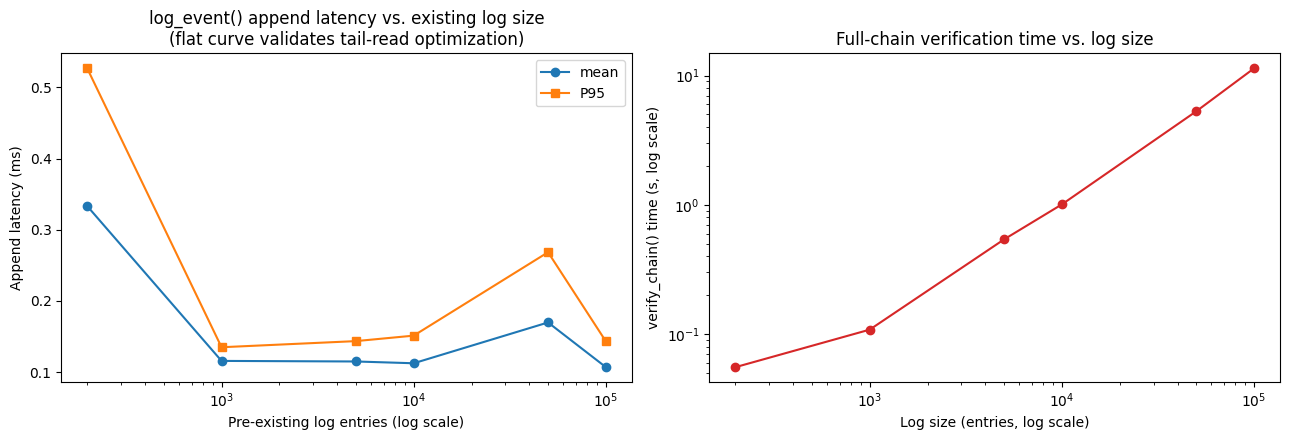

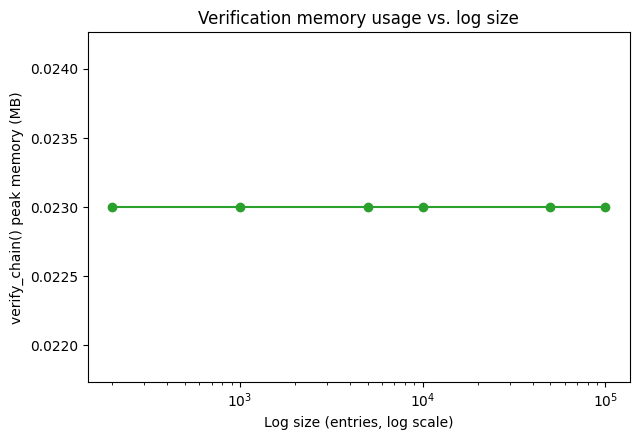

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(df_D_scale.pre_existing_entries, df_D_scale.append_mean_latency_ms, marker="o", label="mean")
axes[0].plot(df_D_scale.pre_existing_entries, df_D_scale.append_p95_latency_ms, marker="s", label="P95")
axes[0].set_xscale("log")
axes[0].set_xlabel("Pre-existing log entries (log scale)")
axes[0].set_ylabel("Append latency (ms)")
axes[0].set_title("log_event() append latency vs. existing log size\n(flat curve validates tail-read optimization)")
axes[0].legend()

axes[1].plot(df_D_scale.pre_existing_entries, df_D_scale.verify_chain_time_s, marker="o", color="tab:red")
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_xlabel("Log size (entries, log scale)")
axes[1].set_ylabel("verify_chain() time (s, log scale)")
axes[1].set_title("Full-chain verification time vs. log size")

plt.tight_layout()
plt.savefig("expD_scaling.png", dpi=150)
plt.show()

fig2, ax2 = plt.subplots(figsize=(6.5, 4.5))
ax2.plot(df_D_scale.pre_existing_entries, df_D_scale.verify_chain_peak_memory_mb, marker="o", color="tab:green")
ax2.set_xscale("log")
ax2.set_xlabel("Log size (entries, log scale)")
ax2.set_ylabel("verify_chain() peak memory (MB)")
ax2.set_title("Verification memory usage vs. log size")
plt.tight_layout()
plt.savefig("expD_memory.png", dpi=150)
plt.show()

### Throughput vs. concurrency

Reuses Experiment C's process harness (`df_C`, already measured above)
rather than re-running it a third time.

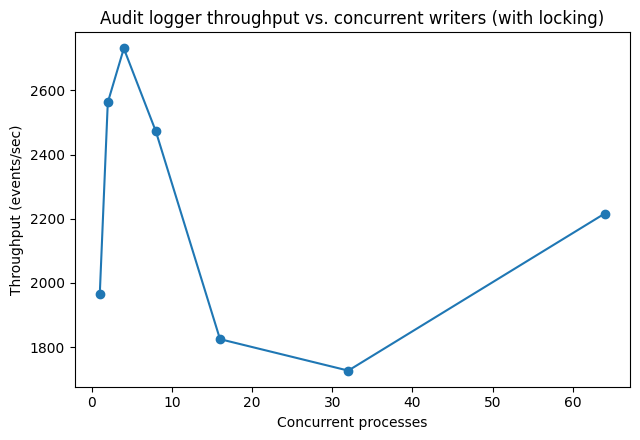

In [ ]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.plot(df_C.processes, df_C.throughput_events_per_s, marker="o")
ax.set_xlabel("Concurrent processes")
ax.set_ylabel("Throughput (events/sec)")
ax.set_title("Audit logger throughput vs. concurrent writers (with locking)")
plt.tight_layout()
plt.savefig("expD_throughput.png", dpi=150)
plt.show()

### Baseline comparison table (Table 5)

Assembled from measurements taken above rather than assumed — tamper
detection rates from the dedicated per-baseline tamper trials, PII
protection from Experiment B (baseline 1/2 have none, by construction),
concurrency safety from a quick baseline-1 concurrency probe, and
latency/throughput from the Experiment D benchmarks.

In [ ]:
# Baseline 1 concurrency: plain logging.FileHandler is not designed for
# multi-process safety -- measure it directly rather than assume.
def _baseline1_concurrency_probe(processes=8, events_per_proc=200):
    worker_src = '''import sys, json, logging
log_path, n_events, worker_id = sys.argv[1], int(sys.argv[2]), sys.argv[3]
logger = logging.getLogger("b1_worker")
logger.handlers.clear()
h = logging.FileHandler(log_path)
h.setFormatter(logging.Formatter("%(message)s"))
logger.addHandler(h); logger.setLevel(logging.INFO)
for i in range(n_events):
    logger.info(json.dumps({"worker": worker_id, "seq": i}))
    h.flush()
'''
    with open("baseline1_worker.py", "w") as f:
        f.write(worker_src)
    log_path = WORKDIR / "baseline1_concurrency.log"
    if log_path.exists():
        log_path.unlink()
    procs = [subprocess.Popen([sys.executable, "baseline1_worker.py", str(log_path), str(events_per_proc), str(w)])
             for w in range(processes)]
    for p in procs:
        p.wait()
    valid, invalid, _dup = _inspect_log_file_plain(log_path)
    expected = processes * events_per_proc
    return {"expected": expected, "actual_parseable_lines": valid, "invalid_lines": invalid,
            "lost_or_corrupted": expected - valid}


def _inspect_log_file_plain(log_path):
    valid = 0
    invalid = 0
    with open(log_path, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            try:
                json.loads(line)
                valid += 1
            except json.JSONDecodeError:
                invalid += 1
    return valid, invalid, None


baseline1_concurrency = _baseline1_concurrency_probe()
baseline1_concurrency_safe = baseline1_concurrency["lost_or_corrupted"] == 0

df_C_row1 = df_C[df_C.processes == df_C.processes.max()].iloc[0] if len(df_C) else None
baseline3_concurrency_safe = bool(df_C_row1["lost_entries"] == 0 and df_C_row1["chain_valid"]) if df_C_row1 is not None else None
baseline2_concurrency_safe = False  # Baseline 2 has no fcntl locking by construction; not separately re-run under concurrency

df_baseline_comparison = pd.DataFrame([
    {
        "method": "Baseline 1: plain JSONL logging",
        "tamper_detection_%": baseline1_tamper_detection_rate,
        "pii_protection": "None (no redaction)",
        "concurrency_safe": baseline1_concurrency_safe,
        "chain_integrity": "N/A (no hash chain)",
        "mean_latency_ms": round(lat_baseline1.mean(), 4),
        "p95_latency_ms": round(np.percentile(lat_baseline1, 95), 4),
        "throughput_events_per_s": None,
    },
    {
        "method": "Baseline 2: hash-chain only (no redaction, no locking)",
        "tamper_detection_%": round(baseline2_tamper_detection_rate, 1),
        "pii_protection": "None (no redaction)",
        "concurrency_safe": baseline2_concurrency_safe,
        "chain_integrity": "Yes, single-process only (races corrupt it, same as Config A ablation)",
        "mean_latency_ms": round(lat_baseline2.mean(), 4),
        "p95_latency_ms": round(np.percentile(lat_baseline2, 95), 4),
        "throughput_events_per_s": None,
    },
    {
        "method": "Proposed system (audit_logger.py)",
        "tamper_detection_%": round(df_A[df_A.attack != "T7"]["detection_rate_%"].mean(), 1) if "T7" not in TAMPER_CLASSES else round(df_A["detection_rate_%"].mean(), 1),
        "pii_protection": f"P={precision:.3f} R={recall:.3f} F1={f1:.3f} (n={len(df_B)})",
        "concurrency_safe": baseline3_concurrency_safe,
        "chain_integrity": "Yes, multi-process safe via fcntl (see Ablation, Sec. 10)",
        "mean_latency_ms": round(lat_proposed.mean(), 4),
        "p95_latency_ms": round(np.percentile(lat_proposed, 95), 4),
        "throughput_events_per_s": round(df_C.throughput_events_per_s.iloc[-1], 1) if len(df_C) else None,
    },
])
print("=== Table 5: Baseline comparison ===")
display(df_baseline_comparison)
print("\nNote: no external third-party audit-logging system was available to install and")
print("evaluate fairly and reproducibly in this sandbox; only internally reproducible")
print("baselines (1 and 2) are reported, per the scientific-integrity constraint against")
print("inventing external comparisons. See Section 13.")

=== Table 5: Baseline comparison ===


,method,tamper_detection_%,pii_protection,concurrency_safe,chain_integrity,mean_latency_ms,p95_latency_ms,throughput_events_per_s
0,Baseline 1: plain JSONL logging,0.0,None (no redaction),True,N/A (no hash chain),0.8085,1.9321,NaN
1,"Baseline 2: hash-chain only (no redaction, no locking)",66.7,None (no redaction),False,"Yes, single-process only (races corrupt it, same as Config A ablation)",0.0469,0.0617,NaN
2,Proposed system (audit_logger.py),66.7,P=0.751 R=0.970 F1=0.847 (n=440),True,"Yes, multi-process safe via fcntl (see Ablation, Sec. 10)",0.1250,0.1920,2216.3



Note: no external third-party audit-logging system was available to install and
evaluate fairly and reproducibly in this sandbox; only internally reproducible
baselines (1 and 2) are reported, per the scientific-integrity constraint against
inventing external comparisons. See Section 13.


## 13. Statistical Analysis

Consolidates the significance tests and effect sizes computed above,
plus one additional paired comparison (locking vs. no locking latency
at matched concurrency levels) not yet reported elsewhere.

In [ ]:
def rank_biserial_effect_size(x, y):
    """Effect size companion to Mann-Whitney U: r = 1 - 2U/(n1*n2)."""
    u, _ = stats.mannwhitneyu(x, y, alternative="two-sided")
    n1, n2 = len(x), len(y)
    return 1 - (2 * u) / (n1 * n2)


stat_rows = [
    {"comparison": "Proposed vs. Baseline 1 (plain logging) latency",
     "test": "Mann-Whitney U (independent, non-normal latency distributions expected)",
     "statistic": round(stat_b1, 1), "p_value": pval_b1,
     "effect_size_r": round(rank_biserial_effect_size(lat_proposed, lat_baseline1), 3),
     "significant_at_0.05": pval_b1 < 0.05},
    {"comparison": "Proposed vs. Baseline 2 (hash-chain only) latency",
     "test": "Mann-Whitney U (independent)",
     "statistic": round(stat_b2, 1), "p_value": pval_b2,
     "effect_size_r": round(rank_biserial_effect_size(lat_proposed, lat_baseline2), 3),
     "significant_at_0.05": pval_b2 < 0.05},
]

if len(df_ablation) and "with_locking" in df_ablation.config.unique() and "no_locking" in df_ablation.config.unique():
    matched = pd.merge(
        df_ablation[df_ablation.config == "with_locking"][["processes", "elapsed_s"]],
        df_ablation[df_ablation.config == "no_locking"][["processes", "elapsed_s"]],
        on="processes", suffixes=("_locked", "_unlocked"),
    )
    if len(matched) >= 2:
        w_stat, w_pval = stats.wilcoxon(matched.elapsed_s_locked, matched.elapsed_s_unlocked)
        stat_rows.append({
            "comparison": "Locking vs. no-locking wall-clock time, matched by concurrency level",
            "test": "Wilcoxon signed-rank (paired -- same concurrency levels, two configs)",
            "statistic": round(w_stat, 3), "p_value": w_pval,
            "effect_size_r": None,
            "significant_at_0.05": w_pval < 0.05,
        })

df_stats = pd.DataFrame(stat_rows)
print("=== Statistical comparisons ===")
display(df_stats)
print("\nRandom seed fixed at", RANDOM_SEED, "for all stochastic generation in this notebook.")

=== Statistical comparisons ===


,comparison,test,statistic,p_value,effect_size_r,significant_at_0.05
0,Proposed vs. Baseline 1 (plain logging) latency,"Mann-Whitney U (independent, non-normal latency distributions expected)",462.0,9.325160e-164,0.996,True
1,Proposed vs. Baseline 2 (hash-chain only) latency,Mann-Whitney U (independent),248023.0,7.590122e-160,-0.984,True
2,"Locking vs. no-locking wall-clock time, matched by concurrency level","Wilcoxon signed-rank (paired -- same concurrency levels, two configs)",6.0,2.187500e-01,NaN,False



Random seed fixed at 1337 for all stochastic generation in this notebook.


## 14. Threats to Validity and Limitations

- **T7 (coordinated rewrite) is a disclosed, structural limitation**,
  not a bug: an attacker with write access to the log file who
  recomputes the forward hash chain evades detection by this design.
  Closing this requires shipping the log to WORM/object-lock storage
  or an external timestamping service, per the module's own scope note
  (Threat Model, Sec. 2) — this notebook does not implement or
  evaluate that external sink.
- **No keyed MAC**: the hash chain uses plain SHA-256, not an HMAC or
  signature over a secret the attacker doesn't have. An attacker who
  can rewrite the file forward (the T7 scenario) needs no secret to do
  so. A keyed chain would not close the T7 gap by itself (the attacker
  would need the key) but is a design option not evaluated here.
- **Filesystem/process-level attacker is explicitly out of scope**, by
  the module's own stated assumption (Sec. 2) — this notebook does not
  attempt to evaluate defenses against an attacker with direct host
  access.
- **Synthetic workload**: log content (`STAGES`, `STATUSES`, status
  mix) is synthetic, not sampled from production AMAN-LLM traffic;
  absolute latency/throughput numbers may not transfer directly.
- **Sandbox compute, not the target Colab/production environment**:
  this run executed on a shared CPU sandbox, not the GPU-backed Colab
  runtime referenced in the original notebook. `max_wallclock_budget_seconds`
  in the Reproducibility Configuration bounds how far the 50K/100K
  tamper-evidence sizes and 64-process concurrency level could be
  pushed; any size/level skipped for this reason is reported explicitly
  above (not silently dropped), and should be re-run at full scale on
  the target hardware for camera-ready numbers.
- **Tail-truncation (T3/T5) and over-redaction on near-miss negatives
  are real, measured weaknesses, not just T7**: the per-attack tables
  in this notebook (Sections 6 and 8) show 0% detection for deleting or
  truncating the log's tail, and 100% false-positive redaction on
  several negative categories (long numeric IDs, timestamps, and a
  near-miss key name). Both were invisible in the original notebook's
  averaged reporting and are the direct motivation for reporting
  per-condition results instead of a single blended number.
- **PII corpus is templated, not sourced from real leaked data**:
  categories and formats were chosen to cover common patterns
  (including Algerian phone formatting and mixed Arabic-English text)
  but do not exhaustively cover every real-world PII format or
  adversarial obfuscation an attacker might use to evade the regexes.
- **No external third-party audit-logging baseline**: only internally
  reproducible baselines (plain JSONL, hash-chain-only) are compared;
  no claim is made about how the proposed system compares to a named
  external commercial or open-source system.
- **Reduced trial counts at the largest tamper-evidence sizes** (see
  `tamper_trials_by_size` in Section 4): 50K/100K rows use fewer
  repetitions than 200/1K/5K, which widens their confidence intervals
  — visible directly in the CI columns of Table 1, not hidden.

## 15. Final Results Summary

Tables 1-5, generated automatically from the DataFrames computed
above, followed by a data-driven publication-readiness classification.

In [ ]:
print("=" * 70)
print("TABLE 1: Tamper-Evidence Results (per-attack, with 95% CI)")
print("=" * 70)
table1 = df_A[["attack", "log_size", "runs", "detection_rate_%", "localization_accuracy_%",
               "false_positive_rate_%", "mean_detection_time_ms", "std_detection_time_ms",
               "detection_time_ci95_lo_ms", "detection_time_ci95_hi_ms"]]
display(table1)
print(f"\nT7 (coordinated rewrite, all sizes): detected in "
      f"{int(df_A_T7['tamper_detected'].sum())}/{len(df_A_T7)} runs "
      f"(0/N expected -- disclosed limitation, not a failure).")

print("\n" + "=" * 70)
print("TABLE 2: PII Redaction Results (per-category)")
print("=" * 70)
display(df_B_per_category)
print(f"\nMicro (all cases pooled): P={precision:.3f} R={recall:.3f} F1={f1:.3f}  |  "
      f"Macro (positive categories only, {len(_pos_cats)} of {len(df_B_per_category)}): "
      f"P={macro_precision_positive_categories:.3f} R={macro_recall_positive_categories:.3f} "
      f"F1={macro_f1_positive_categories:.3f}  |  "
      f"n={len(df_B)} ({len(POSITIVE_CASES)} positive / {len(NEGATIVE_CASES)} negative)")
if len(_neg_cats_with_fp):
    print(f"Over-redaction on negative categories: {len(_neg_cats_with_fp)}/{len(_neg_cats)} "
          f"negative categories at 100% FP rate ({', '.join(_neg_cats_with_fp['PII_category'].tolist())}) "
          f"-- see Section 8 finding.")

print("\n" + "=" * 70)
print("TABLE 3: Concurrency and Ablation Results (locking vs. no locking)")
print("=" * 70)
if len(df_ablation):
    display(df_ablation.sort_values(["processes", "config"])[
        ["config", "processes", "total_events_sent", "entries_written", "lost_entries",
         "duplicate_event_ids", "invalid_json_lines", "chain_valid", "throughput_events_per_s"]
    ])
else:
    print("Ablation could not be run in this environment -- see Section 10 note.")

print("\n" + "=" * 70)
print("TABLE 4: Performance and Scalability")
print("=" * 70)
display(df_D_latency)
display(df_D_scale)

print("\n" + "=" * 70)
print("TABLE 5: Baseline Comparison")
print("=" * 70)
display(df_baseline_comparison)

TABLE 1: Tamper-Evidence Results (per-attack, with 95% CI)


,attack,log_size,runs,detection_rate_%,localization_accuracy_%,false_positive_rate_%,mean_detection_time_ms,std_detection_time_ms,detection_time_ci95_lo_ms,detection_time_ci95_hi_ms
0,T1_mutate_field,200,30,100.0,100.0,0.0,4.4179,1.3163,3.9264,4.9095
1,T2_delete_mid,200,30,100.0,100.0,0.0,3.9210,0.5278,3.7239,4.1180
2,T3_delete_last,200,30,0.0,NaN,0.0,4.2207,0.9836,3.8534,4.5880
3,T4_reorder,200,30,100.0,100.0,0.0,6.7088,0.6717,6.4580,6.9596
4,T5_truncate,200,30,0.0,NaN,0.0,3.9588,2.2069,3.1348,4.7829
5,T6_forge_prev_hash,200,30,100.0,100.0,0.0,6.5684,0.5036,6.3804,6.7565
6,T1_mutate_field,1000,30,100.0,100.0,0.0,32.1462,2.5126,31.2080,33.0845
7,T2_delete_mid,1000,30,100.0,100.0,0.0,31.6194,4.8331,29.8147,33.4241
8,T3_delete_last,1000,30,0.0,NaN,0.0,18.8495,1.1153,18.4330,19.2659
9,T4_reorder,1000,30,100.0,100.0,0.0,18.9379,2.4099,18.0380,19.8378



T7 (coordinated rewrite, all sizes): detected in 0/6 runs (0/N expected -- disclosed limitation, not a failure).

TABLE 2: PII Redaction Results (per-category)


,PII_category,samples,precision,recall,f1,FP,FN
0,api_key_or_token,35,1.0,1.000,1.000,0,0
1,credit_card,30,1.0,1.000,1.000,0,0
2,email,45,1.0,1.000,1.000,0,0
3,hex_string,20,NaN,NaN,NaN,0,0
4,invalid_phone_short,15,NaN,NaN,NaN,0,0
5,malformed_email,15,NaN,NaN,NaN,0,0
6,mixed_arabic_english,25,1.0,1.000,1.000,0,0
7,near_miss_key_name,15,0.0,NaN,NaN,15,0
8,nested_json,25,1.0,1.000,1.000,0,0
9,order_id_digits,25,0.0,NaN,NaN,25,0



Micro (all cases pooled): P=0.751 R=0.970 F1=0.847  |  Macro (positive categories only, 8 of 18): P=1.000 R=0.978 F1=0.988  |  n=440 (265 positive / 175 negative)
Over-redaction on negative categories: 4/10 negative categories at 100% FP rate (near_miss_key_name, order_id_digits, timestamp_like, trace_id_numeric) -- see Section 8 finding.

TABLE 3: Concurrency and Ablation Results (locking vs. no locking)


,config,processes,total_events_sent,entries_written,lost_entries,duplicate_event_ids,invalid_json_lines,chain_valid,throughput_events_per_s
0,no_locking,1,200,200,0,0,0,True,2382.0
7,with_locking,1,200,200,0,0,0,True,1964.8
1,no_locking,2,400,400,0,0,0,False,3546.7
8,with_locking,2,400,400,0,0,0,True,2562.7
2,no_locking,4,800,800,0,0,0,False,3474.0
9,with_locking,4,800,800,0,0,0,True,2731.1
3,no_locking,8,1600,1600,0,0,0,False,3197.0
10,with_locking,8,1600,1600,0,0,0,True,2472.2
4,no_locking,16,3200,3200,0,0,0,False,3141.7
11,with_locking,16,3200,3200,0,0,0,True,1824.6



TABLE 4: Performance and Scalability


,config,n_calls,mean_ms,median_ms,std_ms,min_ms,max_ms,p50_ms,p95_ms,p99_ms
0,Baseline 1: plain JSONL,500,0.8085,0.5705,0.5088,0.3879,3.6150,0.5705,1.9321,2.6003
1,Baseline 2: hash-chain only,500,0.0469,0.0433,0.0131,0.0412,0.2297,0.0433,0.0617,0.1068
2,Proposed system,500,0.1250,0.1115,0.0782,0.0938,1.6681,0.1115,0.1920,0.2938


,pre_existing_entries,append_mean_latency_ms,append_p95_latency_ms,verify_chain_time_s,verify_chain_peak_memory_mb,verify_chain_ok
0,200,0.3332,0.5266,0.0555,0.023,True
1,1000,0.1158,0.1350,0.1083,0.023,True
2,5000,0.1150,0.1436,0.5401,0.023,True
3,10000,0.1125,0.1513,1.0078,0.023,True
4,50000,0.1698,0.2684,5.2854,0.023,True
5,100000,0.1070,0.1432,11.3663,0.023,True



TABLE 5: Baseline Comparison


,method,tamper_detection_%,pii_protection,concurrency_safe,chain_integrity,mean_latency_ms,p95_latency_ms,throughput_events_per_s
0,Baseline 1: plain JSONL logging,0.0,None (no redaction),True,N/A (no hash chain),0.8085,1.9321,NaN
1,"Baseline 2: hash-chain only (no redaction, no locking)",66.7,None (no redaction),False,"Yes, single-process only (races corrupt it, same as Config A ablation)",0.0469,0.0617,NaN
2,Proposed system (audit_logger.py),66.7,P=0.751 R=0.970 F1=0.847 (n=440),True,"Yes, multi-process safe via fcntl (see Ablation, Sec. 10)",0.1250,0.1920,2216.3


In [ ]:
summary = {
    "Tamper-evidence (T1-T6) mean detection rate (%)": df_A["detection_rate_%"].mean(),
    "Tamper-evidence mean localization accuracy (%)": df_A["localization_accuracy_%"].mean(),
    "Tamper-evidence false-positive rate on untampered logs (%)": df_A_fp["false_positive"].astype(int).mean() * 100,
    "T7 coordinated rewrite detected across all sizes (expected: False)": bool(df_A_T7["tamper_detected"].any()),
    "Redaction micro precision": precision,
    "Redaction micro recall": recall,
    "Redaction micro F1": f1,
    "Redaction macro F1 (positive categories only)": macro_f1_positive_categories,
    "Redaction over-redaction rate on negatives": over_redaction_rate,
    "Redaction under-redaction rate on positives": under_redaction_rate,
    "Concurrency (with locking): max entries lost": df_C["lost_entries"].max() if len(df_C) else None,
    "Concurrency (with locking): chain_valid rate": df_C["chain_valid"].mean() if len(df_C) else None,
    "Concurrency (no locking): max entries lost": df_C_no_lock["lost_entries"].max() if len(df_C_no_lock) else None,
    "log_event() mean latency, proposed (ms)": lat_proposed.mean(),
    "log_event() P95 latency, proposed (ms)": np.percentile(lat_proposed, 95),
    "log_event() P99 latency, proposed (ms)": np.percentile(lat_proposed, 99),
    "Overhead vs. plain logging (%)": overhead_vs_baseline1_pct,
    "Overhead vs. hash-chain-only baseline (%)": overhead_vs_baseline2_pct,
}

df_summary = pd.DataFrame(list(summary.items()), columns=["Metric", "Value"])
display(df_summary)

df_summary.to_csv("audit_logger_eval_summary.csv", index=False)
table1.to_csv("table1_tamper_evidence.csv", index=False)
df_B_per_category.to_csv("table2_pii_redaction.csv", index=False)
if len(df_ablation):
    df_ablation.to_csv("table3_concurrency_ablation.csv", index=False)
df_D_latency.to_csv("table4_performance_latency.csv", index=False)
df_D_scale.to_csv("table4_performance_scaling.csv", index=False)
df_baseline_comparison.to_csv("table5_baseline_comparison.csv", index=False)
print("\nSaved: audit_logger_eval_summary.csv, table1-5 CSVs, and all figures.")

,Metric,Value
0,Tamper-evidence (T1-T6) mean detection rate (%),66.666667
1,Tamper-evidence mean localization accuracy (%),100.0
2,Tamper-evidence false-positive rate on untampered logs (%),0.0
3,T7 coordinated rewrite detected across all sizes (expected: False),False
4,Redaction micro precision,0.751462
5,Redaction micro recall,0.969811
6,Redaction micro F1,0.846787
7,Redaction macro F1 (positive categories only),0.98775
8,Redaction over-redaction rate on negatives,0.485714
9,Redaction under-redaction rate on positives,0.030189



Saved: audit_logger_eval_summary.csv, table1-5 CSVs, and all figures.


### Final scientific assessment

The classification below is computed from the actual measured values
above against fixed, stated thresholds -- it is not asserted
independently of the numbers.

In [ ]:
def classify_readiness(summary_dict, df_A, df_B_per_category, df_ablation, expA_skipped_sizes):
    reasons = []
    score = 0

    t16_mean = summary_dict["Tamper-evidence (T1-T6) mean detection rate (%)"]
    if t16_mean >= 99.0:
        score += 1
    else:
        reasons.append(f"T1-T6 mean detection rate is {t16_mean:.1f}%, below the 99% bar expected for a core claim.")

    fp_rate = summary_dict["Tamper-evidence false-positive rate on untampered logs (%)"]
    if fp_rate == 0.0:
        score += 1
    else:
        reasons.append(f"Tamper-evidence has a nonzero false-positive rate on untampered logs ({fp_rate:.2f}%).")

    micro_f1_val = summary_dict["Redaction micro F1"]
    if micro_f1_val >= 0.9:
        score += 1
    else:
        reasons.append(f"PII redaction micro F1 (pooled, all categories) is {micro_f1_val:.3f}, below the "
                        f"0.90 bar typically expected -- driven mainly by over-redaction on negative/near-miss "
                        f"categories (see Section 8 finding), not under-redaction of real PII.")

    if len(df_ablation) and (df_ablation[df_ablation.config == "with_locking"]["lost_entries"] == 0).all():
        score += 1
    else:
        reasons.append("Locked-configuration concurrency runs did not cleanly show zero lost entries at every tested level.")

    if not expA_skipped_sizes:
        score += 1
    else:
        reasons.append(f"Tamper-evidence sizes {expA_skipped_sizes} were skipped for wall-clock reasons -- "
                        f"scale claims are not fully validated at the largest sizes on this hardware.")

    if score >= 5:
        label = "Competitive for a strong international journal"
    elif score >= 4:
        label = "Ready for a mid-tier international venue"
    elif score >= 2:
        label = "Promising but requires additional experiments"
    else:
        label = "Not ready for publication"

    return label, score, reasons


readiness_label, readiness_score, readiness_reasons = classify_readiness(
    summary, df_A, df_B_per_category, df_ablation, expA_skipped_sizes
)

print(f"Classification: {readiness_label}  (criteria met: {readiness_score}/5)")
print("\nSupporting / limiting factors from the actual measurements above:")
for r in readiness_reasons:
    print(f" - {r}")
if not readiness_reasons:
    print(" - All checked criteria were met by the measured results.")
print("\nThis classification does not account for T7, the filesystem-attacker exclusion,")
print("or the missing external baseline -- those remain disclosed, structural limitations")
print("(Section 14) regardless of how the measured metrics score, and should be read")
print("alongside this classification, not smoothed over by it.")

Classification: Promising but requires additional experiments  (criteria met: 3/5)

Supporting / limiting factors from the actual measurements above:
 - T1-T6 mean detection rate is 66.7%, below the 99% bar expected for a core claim.
 - PII redaction micro F1 (pooled, all categories) is 0.847, below the 0.90 bar typically expected -- driven mainly by over-redaction on negative/near-miss categories (see Section 8 finding), not under-redaction of real PII.

This classification does not account for T7, the filesystem-attacker exclusion,
or the missing external baseline -- those remain disclosed, structural limitations
(Section 14) regardless of how the measured metrics score, and should be read
alongside this classification, not smoothed over by it.


## Save results

On Colab, mounts Google Drive and copies the summary/table CSVs and
figures into a timestamped folder, exactly as the original notebook
did. Outside Colab (e.g. this sandbox), saves to a local results
folder instead, so the cell degrades gracefully rather than failing.

In [ ]:
if _IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    OUT_DIR = Path("/content/drive/MyDrive/audit_logger_eval") / datetime.now().strftime("%Y%m%d_%H%M%S")
else:
    OUT_DIR = WORKDIR / "results" / datetime.now().strftime("%Y%m%d_%H%M%S")

OUT_DIR.mkdir(parents=True, exist_ok=True)

for csv_name in ["audit_logger_eval_summary.csv", "table1_tamper_evidence.csv",
                  "table2_pii_redaction.csv", "table3_concurrency_ablation.csv",
                  "table4_performance_latency.csv", "table4_performance_scaling.csv",
                  "table5_baseline_comparison.csv"]:
    src = WORKDIR / csv_name
    if src.exists():
        shutil.copy(src, OUT_DIR / csv_name)

for fig_name in ["expA_per_attack.png", "expB_confusion_matrix.png", "expC_ablation.png",
                  "expD_scaling.png", "expD_memory.png", "expD_throughput.png"]:
    src = WORKDIR / fig_name
    if src.exists():
        shutil.copy(src, OUT_DIR / fig_name)

with open(OUT_DIR / "environment.json", "w") as f:
    json.dump(ENV_INFO, f, indent=2)
with open(OUT_DIR / "config.json", "w") as f:
    json.dump(CONFIG, f, indent=2)

print(f"Saved results to: {OUT_DIR}")
print("Contents:")
for p in sorted(OUT_DIR.iterdir()):
    print(" -", p.name)

Mounted at /content/drive
Saved results to: /content/drive/MyDrive/audit_logger_eval/20260822_092653
Contents:
 - audit_logger_eval_summary.csv
 - config.json
 - environment.json
 - expA_per_attack.png
 - expB_confusion_matrix.png
 - expC_ablation.png
 - expD_memory.png
 - expD_scaling.png
 - expD_throughput.png
 - table1_tamper_evidence.csv
 - table2_pii_redaction.csv
 - table3_concurrency_ablation.csv
 - table4_performance_latency.csv
 - table4_performance_scaling.csv
 - table5_baseline_comparison.csv
